# Identifiez les causes d'attrition au sein d'une ESN

**Contexte.** Une ESN constate un taux de départ d'environ 16 % de ses collaborateurs. L'objectif est de **prédire les démissions** et surtout d'**identifier leurs causes** pour orienter les actions RH.

**Problème.** Classification binaire supervisée sur une cible déséquilibrée (`a_quitte_l_entreprise`).

**Plan**
1. Librairies et configuration
2. Chargement et audit des données
3. Jointure et nettoyage
4. Analyse exploratoire
5. Feature engineering
6. Sélection des variables (corrélations)
7. Préparation des données (encodage)
8. Modélisation : Dummy → régression logistique → XGBoost
9. Interprétabilité : feature importance, permutation, SHAP
10. Identification des employés à risque
11. Conclusion

## 1. Librairies et configuration

Import des librairies et des fonctions du projet (`attrition_esn.ml_utils`). Les chemins (`RAW_DATA_DIR`, `FIGURES_DIR`) sont centralisés dans `attrition_esn.config`.

In [89]:
import pandas as pd
import importlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import preprocessing
import numpy as np

from attrition_esn.config import RAW_DATA_DIR, FIGURES_DIR, MODELS_DIR

import attrition_esn.ml_utils as KF_functions
importlib.reload(KF_functions)
from attrition_esn.ml_utils import data_analyse
from attrition_esn.ml_utils import prepare_data
from attrition_esn.ml_utils import train_evaluate_model
from attrition_esn.ml_utils import perform_cross_validation
from attrition_esn.ml_utils import grid_around_best

In [2]:
pd.set_option('display.max_columns', None)

## 2. Chargement et audit des données

Trois sources RH de 1 470 lignes chacune, à joindre par identifiant employé :
- **SIRH** : données administratives (âge, poste, salaire, ancienneté…)
- **Évaluations** : notes annuelles, satisfactions, heures supplémentaires, augmentation
- **Sondage** : cible `a_quitte_l_entreprise`, PEE, formations, distance, déplacements…

In [3]:
sirh = pd.read_csv(RAW_DATA_DIR / "extrait_sirh.csv")
eval_employee = pd.read_csv(RAW_DATA_DIR / "extrait_eval.csv")
sondage = pd.read_csv(RAW_DATA_DIR / "extrait_sondage.csv")

### 2.1 Fichier SIRH

Audit rapide avec `data_analyse` : aperçu, statistiques, types et valeurs manquantes.

In [4]:
cat_features_sirh = data_analyse(sirh)

Affichage des 5 premières lignes


,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,6,4
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,10,7
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,0,0
3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,8,7
4,7,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,2,2


Taille du fichier SIRH : (1470, 12)
Analyse descriptive


,id_employee,age,revenu_mensuel,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000
mean,1024.865306,36.923810,6502.931293,2.693197,80.0,11.279592,7.008163,4.229252
std,602.024335,9.135373,4707.956783,2.498009,0.0,7.780782,6.126525,3.623137
min,1.000000,18.000000,1009.000000,0.000000,80.0,0.000000,0.000000,0.000000
25%,491.250000,30.000000,2911.000000,1.000000,80.0,6.000000,3.000000,2.000000
50%,1020.500000,36.000000,4919.000000,2.000000,80.0,10.000000,5.000000,3.000000
75%,1555.750000,43.000000,8379.000000,4.000000,80.0,15.000000,9.000000,7.000000
max,2068.000000,60.000000,19999.000000,9.000000,80.0,40.000000,40.000000,18.000000


Types de colonnes
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype
---  ------                          --------------  -----
 0   id_employee                     1470 non-null   int64
 1   age                             1470 non-null   int64
 2   genre                           1470 non-null   str  
 3   revenu_mensuel                  1470 non-null   int64
 4   statut_marital                  1470 non-null   str  
 5   departement                     1470 non-null   str  
 6   poste                           1470 non-null   str  
 7   nombre_experiences_precedentes  1470 non-null   int64
 8   nombre_heures_travailless       1470 non-null   int64
 9   annee_experience_totale         1470 non-null   int64
 10  annees_dans_l_entreprise        1470 non-null   int64
 11  annees_dans_le_poste_actuel     1470 non-null   int64
dtypes: int64(8), str(4)
memory usage: 191.1 KB


None

Valeurs manquates :
id_employee                       0
age                               0
genre                             0
revenu_mensuel                    0
statut_marital                    0
departement                       0
poste                             0
nombre_experiences_precedentes    0
nombre_heures_travailless         0
annee_experience_totale           0
annees_dans_l_entreprise          0
annees_dans_le_poste_actuel       0
dtype: int64


In [5]:
cat_features_sirh

['genre', 'statut_marital', 'departement', 'poste']

### 2.2 Fichier des évaluations

In [6]:
cat_features_eval_employee = data_analyse(eval_employee)

Affichage des 5 premières lignes


,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,eval_number,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente
0,2,3,2,4,1,1,E_1,3,Oui,11 %
1,3,2,2,2,4,3,E_2,4,Non,23 %
2,4,2,1,3,2,3,E_4,3,Oui,15 %
3,4,3,1,3,3,3,E_5,3,Oui,11 %
4,1,3,1,2,4,3,E_7,3,Non,12 %


Taille du fichier SIRH : (1470, 10)
Analyse descriptive


,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,note_evaluation_actuelle
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,2.721769,2.729932,2.063946,2.728571,2.712245,2.761224,3.153741
std,1.093082,0.711561,1.106940,1.102846,1.081209,0.706476,0.360824
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000
25%,2.000000,2.000000,1.000000,2.000000,2.000000,2.000000,3.000000
50%,3.000000,3.000000,2.000000,3.000000,3.000000,3.000000,3.000000
75%,4.000000,3.000000,3.000000,4.000000,4.000000,3.000000,3.000000
max,4.000000,4.000000,5.000000,4.000000,4.000000,4.000000,4.000000


Types de colonnes
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 10 columns):
 #   Column                                     Non-Null Count  Dtype
---  ------                                     --------------  -----
 0   satisfaction_employee_environnement        1470 non-null   int64
 1   note_evaluation_precedente                 1470 non-null   int64
 2   niveau_hierarchique_poste                  1470 non-null   int64
 3   satisfaction_employee_nature_travail       1470 non-null   int64
 4   satisfaction_employee_equipe               1470 non-null   int64
 5   satisfaction_employee_equilibre_pro_perso  1470 non-null   int64
 6   eval_number                                1470 non-null   str  
 7   note_evaluation_actuelle                   1470 non-null   int64
 8   heure_supplementaires                      1470 non-null   str  
 9   augementation_salaire_precedente           1470 non-null   str  
dtypes: int64(7), str(3)
memory usage: 132.9 K

None

Valeurs manquates :
satisfaction_employee_environnement          0
note_evaluation_precedente                   0
niveau_hierarchique_poste                    0
satisfaction_employee_nature_travail         0
satisfaction_employee_equipe                 0
satisfaction_employee_equilibre_pro_perso    0
eval_number                                  0
note_evaluation_actuelle                     0
heure_supplementaires                        0
augementation_salaire_precedente             0
dtype: int64


In [7]:
cat_features_eval_employee

['eval_number', 'heure_supplementaires', 'augementation_salaire_precedente']

**Nettoyage des évaluations**
- `eval_number` (format `E_123`) → extraction de la partie numérique pour servir de clé de jointure avec `id_employee`.
- `augementation_salaire_precedente` (`"11 %"`) → conversion en entier : la variable est quantitative, pas catégorielle.

In [8]:
# considérer la colonne 'eval_number' du fichier eval_employee comme la colonne 'id_employee' du fichier sirh
eval_employee['eval_number'] = (eval_employee['eval_number'].astype(str).str.extract(r"(\d+)").astype(int))
#eval_employee['eval_number'] = (eval_employee['eval_number'].astype(str).replace('E_', '', regex=False).astype(int))
eval_employee['eval_number']

0          1
1          2
2          4
3          5
4          7
        ... 
1465    2061
1466    2062
1467    2064
1468    2065
1469    2068
Name: eval_number, Length: 1470, dtype: int64

In [9]:
# supprimer % de la colonne 'augementation_salaire_precedente' et la considérer comme une colonne quantitative
eval_employee['augementation_salaire_precedente'] = (eval_employee['augementation_salaire_precedente'].str.replace('%', '', regex=False).astype(int))
eval_employee['augementation_salaire_precedente']

0       11
1       23
2       15
3       11
4       12
        ..
1465    17
1466    15
1467    20
1468    14
1469    12
Name: augementation_salaire_precedente, Length: 1470, dtype: int64

In [10]:
# eval_employee['heure_supplementaires'] = (eval_employee['heure_supplementaires'].map({'Oui': 1, 'Non': 0}))
# eval_employee['heure_supplementaires']

In [11]:
cat_features_eval_employee = [c for c in cat_features_eval_employee
                              if c not in ['eval_number', 'augementation_salaire_precedente']]
display(cat_features_eval_employee)

['heure_supplementaires']

### 2.3 Fichier sondage

In [12]:
cat_features_sondage = data_analyse(sondage)

Affichage des 5 premières lignes


,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,code_sondage,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
0,Oui,0,0,1,1,1,2,Infra & Cloud,Y,Occasionnel,0,5
1,Non,1,3,1,2,8,1,Infra & Cloud,Y,Frequent,1,7
2,Oui,0,3,1,4,2,2,Autre,Y,Occasionnel,0,0
3,Non,0,3,1,5,3,4,Infra & Cloud,Y,Frequent,3,0
4,Non,1,3,1,7,2,1,Transformation Digitale,Y,Occasionnel,2,2


Taille du fichier SIRH : (1470, 12)
Analyse descriptive


,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,code_sondage,distance_domicile_travail,niveau_education,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
count,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,0.793878,2.799320,1.0,1024.865306,9.192517,2.912925,2.187755,4.123129
std,0.852077,1.289271,0.0,602.024335,8.106864,1.024165,3.222430,3.568136
min,0.000000,0.000000,1.0,1.000000,1.000000,1.000000,0.000000,0.000000
25%,0.000000,2.000000,1.0,491.250000,2.000000,2.000000,0.000000,2.000000
50%,1.000000,3.000000,1.0,1020.500000,7.000000,3.000000,1.000000,3.000000
75%,1.000000,3.000000,1.0,1555.750000,14.000000,4.000000,3.000000,7.000000
max,3.000000,6.000000,1.0,2068.000000,29.000000,5.000000,15.000000,17.000000


Types de colonnes
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 12 columns):
 #   Column                               Non-Null Count  Dtype
---  ------                               --------------  -----
 0   a_quitte_l_entreprise                1470 non-null   str  
 1   nombre_participation_pee             1470 non-null   int64
 2   nb_formations_suivies                1470 non-null   int64
 3   nombre_employee_sous_responsabilite  1470 non-null   int64
 4   code_sondage                         1470 non-null   int64
 5   distance_domicile_travail            1470 non-null   int64
 6   niveau_education                     1470 non-null   int64
 7   domaine_etude                        1470 non-null   str  
 8   ayant_enfants                        1470 non-null   str  
 9   frequence_deplacement                1470 non-null   str  
 10  annees_depuis_la_derniere_promotion  1470 non-null   int64
 11  annes_sous_responsable_actuel        1470 non-nul

None

Valeurs manquates :
a_quitte_l_entreprise                  0
nombre_participation_pee               0
nb_formations_suivies                  0
nombre_employee_sous_responsabilite    0
code_sondage                           0
distance_domicile_travail              0
niveau_education                       0
domaine_etude                          0
ayant_enfants                          0
frequence_deplacement                  0
annees_depuis_la_derniere_promotion    0
annes_sous_responsable_actuel          0
dtype: int64


In [13]:
cat_features_sondage

['a_quitte_l_entreprise',
 'domaine_etude',
 'ayant_enfants',
 'frequence_deplacement']

Distribution des modalités et de la cible :

In [14]:
# domaine d'étude
sondage['domaine_etude'].value_counts()

domaine_etude
Infra & Cloud              606
Transformation Digitale    464
Marketing                  159
Entrepreunariat            132
Autre                       82
Ressources Humaines         27
Name: count, dtype: int64

In [15]:
# employee ayant des enfants
sondage['ayant_enfants'].value_counts()

ayant_enfants
Y    1470
Name: count, dtype: int64

In [16]:
# employee frequence_deplacement
sondage['frequence_deplacement'].value_counts()

frequence_deplacement
Occasionnel    1043
Frequent        277
Aucun           150
Name: count, dtype: int64

In [17]:
# employee qui ont quitté l'entreprise
sondage['a_quitte_l_entreprise'].value_counts(normalize=True)

a_quitte_l_entreprise
Non    0.838776
Oui    0.161224
Name: proportion, dtype: float64

> **Bilan de l'audit** : aucune valeur manquante. `ayant_enfants` est **constante** (Y pour tous) et donc sans information. La cible est **déséquilibrée** : 16 % de départs contre 84 % de maintiens, ce qui conditionne le choix des métriques (section 8).

## 3. Jointure et nettoyage

Jointure **gauche** sur l'identifiant employé (SIRH → évaluations → sondage). La forme (1 470 lignes) et la proportion de départs (16 %) sont inchangées : aucune perte ni duplication.

In [18]:
data_merged = sirh.merge(eval_employee,left_on='id_employee', right_on='eval_number',how='left')
data_employee = data_merged.merge(sondage,left_on='id_employee', right_on='code_sondage', how='left')
data_employee

,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,eval_number,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,code_sondage,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,6,4,2,3,2,4,1,1,1,3,Oui,11,Oui,0,0,1,1,1,2,Infra & Cloud,Y,Occasionnel,0,5
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,10,7,3,2,2,2,4,3,2,4,Non,23,Non,1,3,1,2,8,1,Infra & Cloud,Y,Frequent,1,7
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,0,0,4,2,1,3,2,3,4,3,Oui,15,Oui,0,3,1,4,2,2,Autre,Y,Occasionnel,0,0
3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,8,7,4,3,1,3,3,3,5,3,Oui,11,Non,0,3,1,5,3,4,Infra & Cloud,Y,Frequent,3,0
4,7,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,2,2,1,3,1,2,4,3,7,3,Non,12,Non,1,3,1,7,2,1,Transformation Digitale,Y,Occasionnel,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,2061,36,M,2571,Marié(e),Consulting,Consultant,4,80,17,5,2,3,4,2,4,3,3,2061,3,Non,17,Non,1,3,1,2061,23,2,Transformation Digitale,Y,Frequent,0,3
1466,2062,39,M,9991,Marié(e),Consulting,Manager,4,80,9,7,7,4,2,3,1,1,3,2062,3,Non,15,Non,1,5,1,2062,6,1,Transformation Digitale,Y,Occasionnel,1,7
1467,2064,27,M,6142,Marié(e),Consulting,Tech Lead,1,80,6,6,2,2,4,2,2,2,3,2064,4,Oui,20,Non,1,0,1,2064,4,3,Infra & Cloud,Y,Occasionnel,0,3
1468,2065,49,M,5390,Marié(e),Commercial,Cadre Commercial,2,80,17,9,6,4,2,2,2,4,2,2065,3,Non,14,Non,0,3,1,2065,2,3,Transformation Digitale,Y,Frequent,0,8


In [19]:
data_employee.shape

(1470, 34)

In [20]:
# employee qui ont quitté l'entreprise
data_employee['a_quitte_l_entreprise'].value_counts(normalize=True)

a_quitte_l_entreprise
Non    0.838776
Oui    0.161224
Name: proportion, dtype: float64

Suppression des colonnes inutiles :
- `eval_number`, `code_sondage` : clés de jointure redondantes avec `id_employee` ;
- `ayant_enfants`, `nombre_employee_sous_responsabilite`, `nombre_heures_travailless` : valeurs constantes ou incohérentes.

In [21]:
cols_to_drop = ['eval_number', # redondant avec id_empleyee
                'code_sondage', # redondant avec id_empleyee
                'nombre_employee_sous_responsabilite', # incohérente
                'ayant_enfants',# incohérente
                'nombre_heures_travailless'] # incohérente

data_employee = data_employee.drop(columns=[col for col in cols_to_drop if col in data_employee.columns])
data_employee.shape

(1470, 29)

Séparation des variables qualitatives et quantitatives pour l'analyse exploratoire :

In [22]:
cat_features = list(data_employee.select_dtypes(include=['str']).columns)
cat_features = [col for col in cat_features if col != 'a_quitte_l_entreprise']
cat_features

['genre',
 'statut_marital',
 'departement',
 'poste',
 'heure_supplementaires',
 'domaine_etude',
 'frequence_deplacement']

In [23]:
num_features = [col for col in data_employee.columns if col not in cat_features]
num_features = [col for col in num_features if (col not in ['id_employee','a_quitte_l_entreprise'])]
#num_features = [col for col in num_features if col != 'a_quitte_l_entreprise']
num_features

['age',
 'revenu_mensuel',
 'nombre_experiences_precedentes',
 'annee_experience_totale',
 'annees_dans_l_entreprise',
 'annees_dans_le_poste_actuel',
 'satisfaction_employee_environnement',
 'note_evaluation_precedente',
 'niveau_hierarchique_poste',
 'satisfaction_employee_nature_travail',
 'satisfaction_employee_equipe',
 'satisfaction_employee_equilibre_pro_perso',
 'note_evaluation_actuelle',
 'augementation_salaire_precedente',
 'nombre_participation_pee',
 'nb_formations_suivies',
 'distance_domicile_travail',
 'niveau_education',
 'annees_depuis_la_derniere_promotion',
 'annes_sous_responsable_actuel']

In [24]:
target = data_employee['a_quitte_l_entreprise']

## 4. Analyse exploratoire

Comparaison de la distribution de chaque variable entre les employés partis (`Oui`) et restés (`Non`).

### 4.1 Variables quantitatives

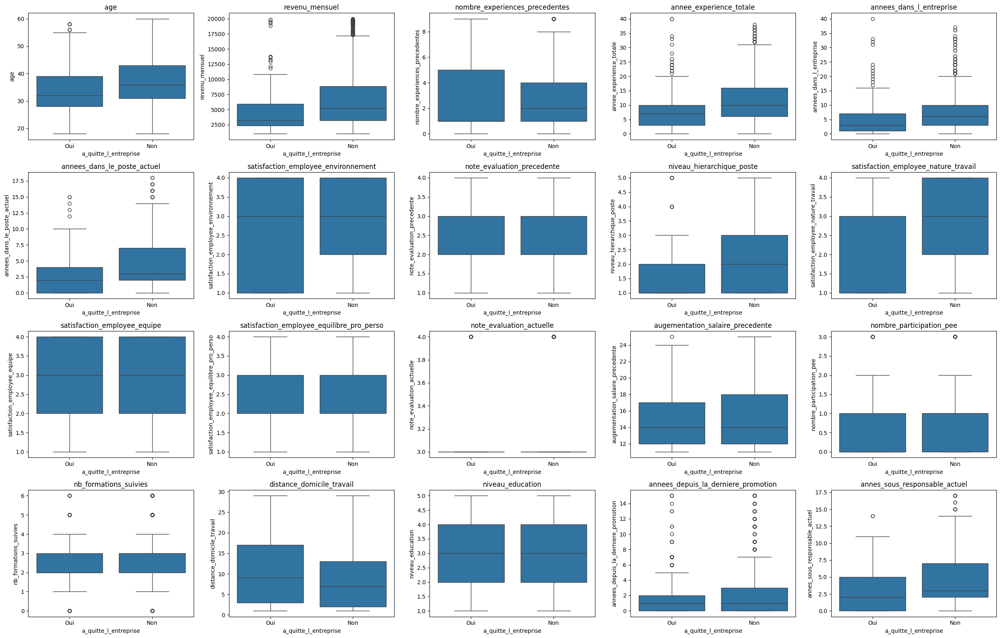

In [25]:
# n_cols = 2
# n_rows = round(len(num_features) / n_cols)+1

n_cols = 5
n_rows = 4

plt.figure(figsize=(5 * n_cols, 4*n_rows))

for i, col in enumerate(num_features):
    plt.subplot(n_rows, n_cols, i+1 )
    sns.boxplot(
        x='a_quitte_l_entreprise',
        y=col,
        data=data_employee
        #showfliers = False
    )
    plt.title(col)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'analyse_descriptive_num.png', dpi=300)
plt.show()


### 4.2 Variables qualitatives

En effectifs, puis en **pourcentage par modalité** (plus lisible, la cible étant déséquilibrée).

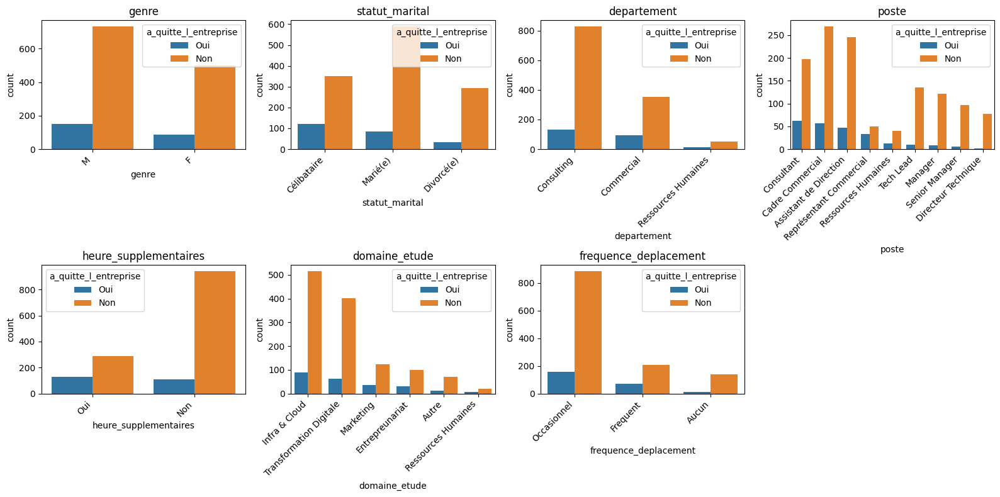

In [26]:
n_cols = 4
n_rows = 2

plt.figure(figsize=(4* n_cols, 4*n_rows))

# plt.figure(figsize=(12, 5 * n_rows))

for i, col in enumerate(cat_features):
    plt.subplot(n_rows, n_cols, i + 1)
    order = (data_employee.groupby(col)['a_quitte_l_entreprise'].apply(lambda x: (x == 'Oui').sum()).sort_values(ascending=False).index)
    sns.countplot(x=col, hue='a_quitte_l_entreprise', data=data_employee,order=order)
    plt.title(col)
    plt.xticks(rotation=45,ha='right')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'analyse_descriptive_cat.png', dpi=300)
plt.show()

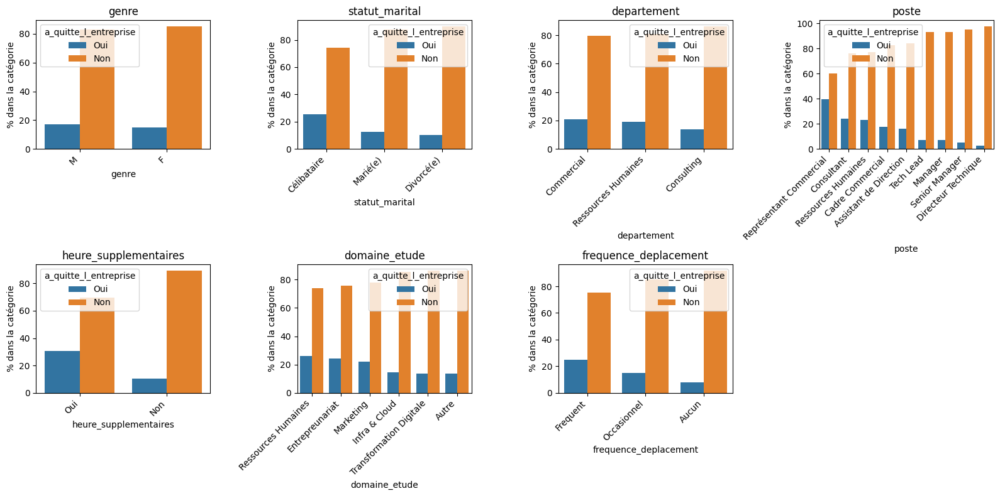

In [27]:
# tracé des variables cat. en % 
n_cols = 4
n_rows = 2
plt.figure(figsize=(4*n_cols, 4*n_rows))

for i, col in enumerate(cat_features):
    plt.subplot(n_rows, n_cols, i+1)

    tab = (
        data_employee.groupby(col)['a_quitte_l_entreprise']
        .value_counts(normalize=True)
        .mul(100)
        .rename('percent')
        .reset_index()
    )

    order = (
        tab[tab['a_quitte_l_entreprise'] == 'Oui']
        .sort_values('percent', ascending=False)[col]
    )

    sns.barplot(
        data=tab,
        x=col,
        y='percent',
        hue='a_quitte_l_entreprise',
        hue_order=['Oui', 'Non'],
        order=order
    )

    plt.title(col)
    plt.xticks(rotation=45, ha='right')
    plt.ylabel('% dans la catégorie')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'analyse_descriptive_cat_percentage.png', dpi=300)
plt.show()

> **À retenir de l'EDA**
> - Les partants sont en moyenne **plus jeunes**, **moins payés**, avec **moins d'ancienneté** et un **niveau hiérarchique plus bas**.
> - Taux de départ nettement plus élevé chez les employés faisant des **heures supplémentaires** (~30 % vs ~10 %), en **déplacements fréquents**, **célibataires**, et sur certains postes (**Représentant commercial** ~40 %, Consultant).
> - Les postes à responsabilité (Manager, Directeur technique…) partent très peu.

## 5. Feature engineering

Création de 10 variables métier pour capter des mécanismes de départ que les variables brutes n'expriment pas directement : dynamique de performance, satisfaction globale, rémunération relative, surcharge et évolution de carrière.

### 5.1 Variation de la note d'évaluation

`note_evaluation_actuelle − note_evaluation_precedente` : progression ou régression de la performance perçue.

In [28]:
# variable 1
data_employee['note_evaluation_variation'] = data_employee['note_evaluation_actuelle']-data_employee['note_evaluation_precedente']
data_employee['note_evaluation_variation'].value_counts()

note_evaluation_variation
 0    757
 1    448
 2    124
-1    124
 3     17
Name: count, dtype: int64

### 5.2 Satisfaction moyenne et vote de satisfaction

- `satisfaction_moyenne` : moyenne des 4 satisfactions (environnement, nature du travail, équipe, équilibre pro/perso).
- `satisfaction_vote` : 1 si `satisfaction_moyenne ≥ 2,5` (satisfait), 0 sinon.

In [29]:
# moyenne globale de satisfaction
data_employee['satisfaction_moyenne'] = data_employee[[col for col in data_employee.columns if col.startswith('satisfaction_')]].mean(axis=1)
data_employee['satisfaction_moyenne'].value_counts()

satisfaction_moyenne
2.75    272
3.00    265
2.50    239
2.25    196
3.25    185
3.50    106
2.00     98
1.75     38
3.75     35
1.50     23
4.00      6
1.25      6
1.00      1
Name: count, dtype: int64

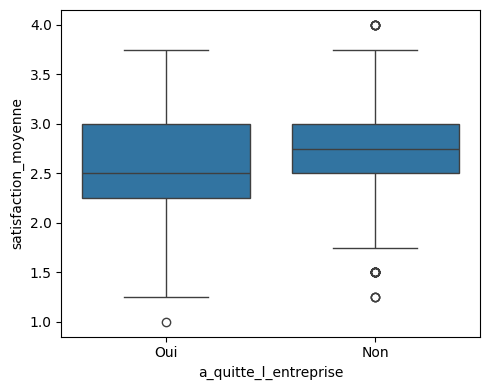

In [30]:
plt.figure(figsize=(5,4))
sns.boxplot(
        x="a_quitte_l_entreprise",
        y='satisfaction_moyenne',
        data=data_employee
        #showfliers = False
    )
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'satisfaction_moyenne.png', dpi=300)
plt.show()

Choix du seuil du vote : 2,5 correspond au 1er quartile, ce qui isole le quart des employés les moins satisfaits.

In [31]:
data_employee['satisfaction_moyenne'].describe()

count    1470.000000
mean        2.730952
std         0.505815
min         1.000000
25%         2.500000
50%         2.750000
75%         3.000000
max         4.000000
Name: satisfaction_moyenne, dtype: float64

In [32]:
# variable 2
data_employee['satisfaction_vote'] = (data_employee['satisfaction_moyenne'] >= 2.5).astype(int)
data_employee['satisfaction_vote'].value_counts()

satisfaction_vote
1    1108
0     362
Name: count, dtype: int64

In [33]:
#sns.countplot(x='satisfaction_vote', hue='a_quitte_l_entreprise', data=data_employee)

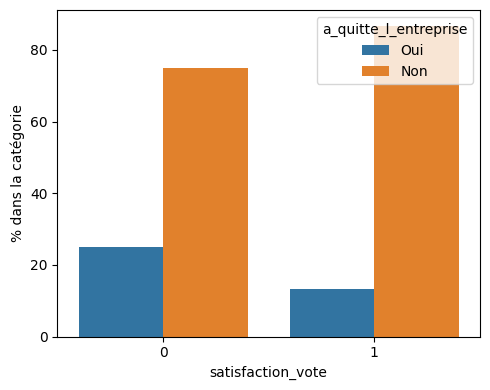

In [34]:
# figure avec %
plt.figure(figsize=(5,4))

tab = (
    data_employee.groupby('satisfaction_vote')['a_quitte_l_entreprise']
    .value_counts(normalize=True)
    .mul(100)
    .rename('percent')
    .reset_index()
)

order = (
    tab[tab['a_quitte_l_entreprise'] == 'Oui']
    .sort_values('percent', ascending=False)['satisfaction_vote']
)

sns.barplot(
    data=tab,
    x='satisfaction_vote',
    y='percent',
    hue='a_quitte_l_entreprise',
    hue_order=['Oui', 'Non'],
    order=order
)

#plt.title("Impact de la satisfaction sur le départ des employés")
#plt.xticks(rotation=45)
plt.ylabel('% dans la catégorie')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'analyse_satisfaction_vote.png', dpi=300)
plt.show()

### 5.3 Évaluation en hausse et satisfaction

`evaluation_satisfaction` = 1 si la note progresse **et** l'employé est satisfait (profil « engagé »).

In [35]:
data_employee['evaluation_satisfaction'] = ((data_employee['note_evaluation_variation']>0) &  (data_employee['satisfaction_vote']==1)).astype(int)
data_employee['evaluation_satisfaction'].value_counts()

evaluation_satisfaction
0    1023
1     447
Name: count, dtype: int64

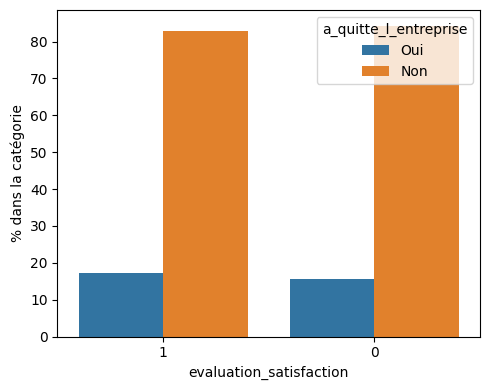

In [36]:
# figure avec %
plt.figure(figsize=(5,4))

tab = (
    data_employee.groupby('evaluation_satisfaction')['a_quitte_l_entreprise']
    .value_counts(normalize=True)
    .mul(100)
    .rename('percent')
    .reset_index()
)

order = (
    tab[tab['a_quitte_l_entreprise'] == 'Oui']
    .sort_values('percent', ascending=False)['evaluation_satisfaction']
)

sns.barplot(
    data=tab,
    x='evaluation_satisfaction',
    y='percent',
    hue='a_quitte_l_entreprise',
    hue_order=['Oui', 'Non'],
    order=order
)

#plt.title("Impact de la satisfaction sur le départ des employés")
#plt.xticks(rotation=45)
plt.ylabel('% dans la catégorie')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'analyse_evaluation_satisfaction.png', dpi=300)
plt.show()

### 5.4 Satisfaction rapportée à l'ancienneté

`satisfaction_moyenne / (annees_dans_l_entreprise + 1)` : une satisfaction élevée chez un nouvel arrivant n'a pas le même sens que chez un ancien (+1 évite la division par zéro).

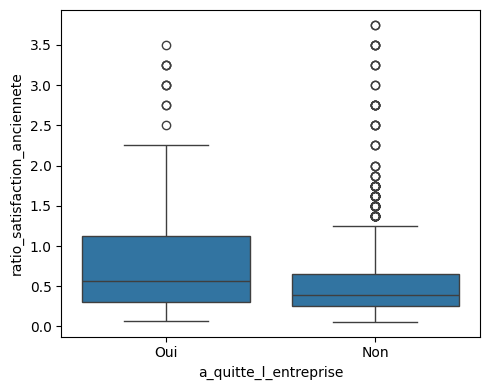

In [37]:
data_employee['ratio_satisfaction_anciennete'] = (data_employee['satisfaction_moyenne']/(data_employee['annees_dans_l_entreprise']+1))

# fig
plt.figure(figsize=(5,4))
sns.boxplot(
        x='a_quitte_l_entreprise',
        y='ratio_satisfaction_anciennete',
        data=data_employee
        #showfliers = False
    )

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'ratio_satisfaction_anciennete.png', dpi=300)
plt.show()

### 5.5 Risque de burnout

`risque_burnout` = 1 si l'employé est **non satisfait** et fait des **heures supplémentaires**.

In [38]:
data_employee['risque_burnout'] = ((data_employee['satisfaction_vote'] == 0) &(data_employee['heure_supplementaires'] == 'Oui')).astype(int)

pd.crosstab(data_employee["risque_burnout"], data_employee["a_quitte_l_entreprise"], normalize="index")

a_quitte_l_entreprise,Non,Oui
risque_burnout,,
0,0.857556,0.142444
1,0.540230,0.459770


Le croisement est très discriminant : **46 % de départs** chez les employés à risque de burnout, contre 14 % pour les autres.

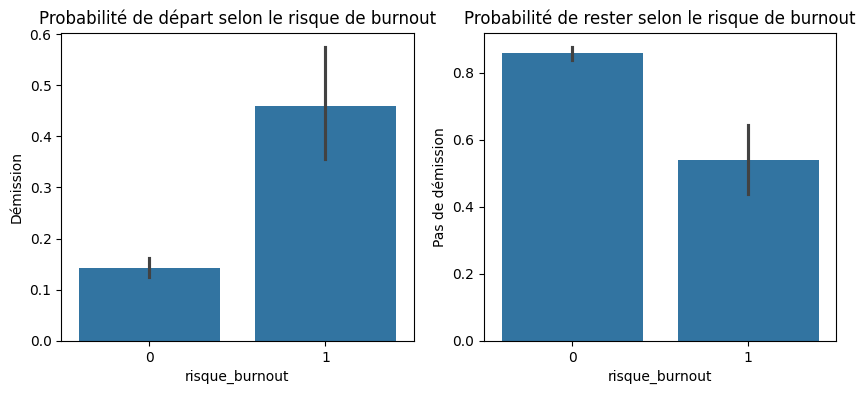

In [39]:
# tracé des probabilité
plt.figure(figsize=(10,4))
plt.subplot(1, 2,1)
# probabilités de quitter l'entreprise 
sns.barplot(x='risque_burnout', y=(data_employee['a_quitte_l_entreprise'] == 'Oui').astype(int), data=data_employee)
plt.title('Probabilité de départ selon le risque de burnout')
plt.ylabel('Démission')


plt.subplot(1, 2,2)
# probabilités de rester dans l'entreprise 
sns.barplot(x='risque_burnout', y=(data_employee['a_quitte_l_entreprise'] == 'Non').astype(int), data=data_employee)
plt.title('Probabilité de rester selon le risque de burnout')
plt.ylabel('Pas de démission')
plt.savefig(FIGURES_DIR / 'proba_demission_burnout.png', dpi=300)
plt.show()

### 5.6 Salaire relatif au poste

`ratio_salaire_moyen_poste` = revenu / salaire moyen du poste : un ratio < 1 signale un employé moins bien payé que ses pairs.

In [40]:
# calcul du salaire moyen par poste
data_employee['salaire_moyen_poste'] = (data_employee.groupby('poste')['revenu_mensuel'].transform('mean'))

In [41]:
data_employee['ratio_salaire_moyen_poste'] = (data_employee['revenu_mensuel']/data_employee['salaire_moyen_poste'])
data_employee.groupby('a_quitte_l_entreprise')['ratio_salaire_moyen_poste'].describe().T

a_quitte_l_entreprise,Non,Oui
count,1233.000000,237.000000
mean,1.009116,0.952575
std,0.341932,0.355130
min,0.324385,0.311422
25%,0.752475,0.716364
50%,0.936930,0.847345
75%,1.185604,1.155824
max,3.001260,2.474650


Les partants sont moins bien payés que leurs pairs à poste égal (ratio médian **0,85** contre 0,94).

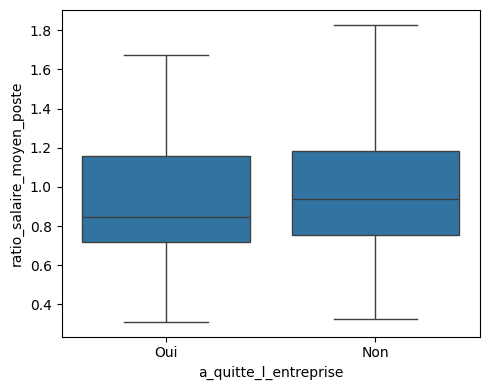

In [42]:
plt.figure(figsize=(5,4))
sns.boxplot(
        x='a_quitte_l_entreprise',
        y='ratio_salaire_moyen_poste',
        data=data_employee,
        showfliers = False
    )
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'ratio_salaire_moyen_poste.png', dpi=300)
plt.show()

### 5.7 Salaire relatif au poste et au département

Même logique, avec une référence plus fine (poste × département).

In [43]:
# salaire moyen par poste par département
data_employee['salaire_moyen_poste_departement'] = (data_employee.groupby(['departement', 'poste'])['revenu_mensuel'] .transform('mean'))

# ratio entre salaire mensuel et salaire moyen par poste par département
data_employee['ratio_salaire_moyen_poste_departement'] = (data_employee['revenu_mensuel'] /data_employee['salaire_moyen_poste_departement'])
data_employee.groupby('a_quitte_l_entreprise')['ratio_salaire_moyen_poste_departement'].describe().T

a_quitte_l_entreprise,Non,Oui
count,1233.000000,237.000000
mean,1.009088,0.952718
std,0.341895,0.355183
min,0.324385,0.311422
25%,0.752475,0.716364
50%,0.937238,0.847345
75%,1.185604,1.158035
max,3.001260,2.474650


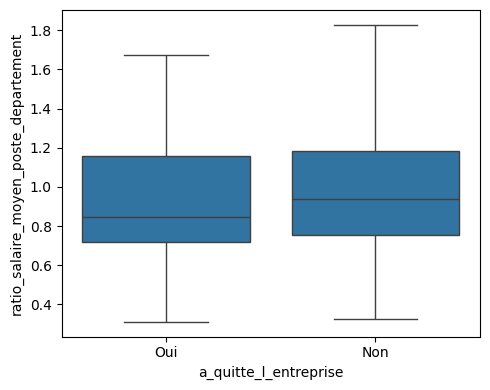

In [44]:
plt.figure(figsize=(5,4))
sns.boxplot(
        x='a_quitte_l_entreprise',
        y='ratio_salaire_moyen_poste_departement',
        data=data_employee,
        showfliers = False
    )
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'ratio_salaire_moyen_poste_departement.png', dpi=300)
plt.show()

### 5.8 Non satisfait et sous-payé

`non_satisfait_sous_paye` = 1 si `satisfaction_vote = 0` **et** `ratio_salaire_moyen_poste_departement < 1`.

In [45]:
data_employee['non_satisfait_sous_paye'] = ((data_employee['satisfaction_vote'] == 0) & (data_employee['ratio_salaire_moyen_poste_departement'] < 1)).astype(int)
data_employee['non_satisfait_sous_paye']

0       1
1       0
2       0
3       0
4       0
       ..
1465    0
1466    0
1467    1
1468    0
1469    0
Name: non_satisfait_sous_paye, Length: 1470, dtype: int64

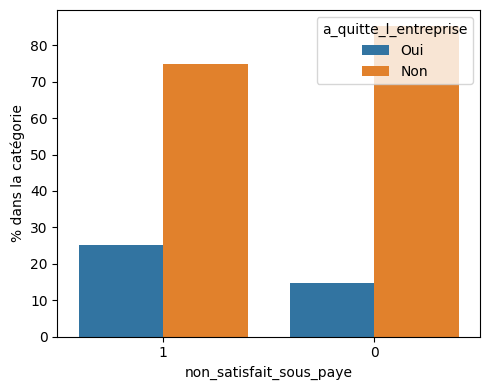

In [46]:
# figure avec %
plt.figure(figsize=(5,4))

tab = (
    data_employee.groupby('non_satisfait_sous_paye')['a_quitte_l_entreprise']
    .value_counts(normalize=True)
    .mul(100)
    .rename('percent')
    .reset_index()
)

order = (
    tab[tab['a_quitte_l_entreprise'] == 'Oui']
    .sort_values('percent', ascending=False)['non_satisfait_sous_paye']
)

sns.barplot(
    data=tab,
    x='non_satisfait_sous_paye',
    y='percent',
    hue='a_quitte_l_entreprise',
    hue_order=['Oui', 'Non'],
    order=order
)

#plt.title("Impact de la satisfaction sur le départ des employés")
#plt.xticks(rotation=45)
plt.ylabel('% dans la catégorie')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'non_satisfait_sous_paye.png', dpi=300)
plt.show()

### 5.9 Mobilité interne

`annees_dans_l_entreprise − annees_dans_le_poste_actuel` : années passées sur d'autres postes de l'entreprise.

In [47]:
data_employee['mobilite_interne'] = (data_employee['annees_dans_l_entreprise'] - data_employee['annees_dans_le_poste_actuel'])
data_employee['mobilite_interne'].describe()

count    1470.000000
mean        2.778912
std         4.120310
min         0.000000
25%         1.000000
50%         1.000000
75%         3.000000
max        30.000000
Name: mobilite_interne, dtype: float64

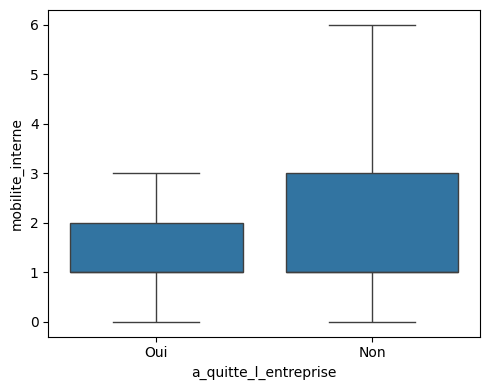

In [48]:
plt.figure(figsize=(5,4))
sns.boxplot(
        x='a_quitte_l_entreprise',
        y='mobilite_interne',
        data=data_employee,
        showfliers = False
    )
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'mobilite_interne.png', dpi=300)
plt.show()

### 5.10 Ratio de stagnation

`annees_dans_le_poste_actuel / (annees_dans_l_entreprise + 1)` : proche de 1, l'employé n'a jamais changé de poste.

In [49]:
data_employee['stagnation_ratio'] = (data_employee['annees_dans_le_poste_actuel'] /(data_employee['annees_dans_l_entreprise'] + 1))
data_employee['stagnation_ratio'].describe()

count    1470.000000
mean        0.480701
std         0.274128
min         0.000000
25%         0.333333
50%         0.500000
75%         0.666667
max         0.882353
Name: stagnation_ratio, dtype: float64

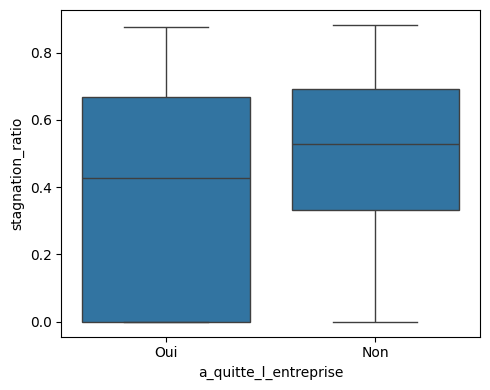

In [50]:
plt.figure(figsize=(5,4))
sns.boxplot(
        x='a_quitte_l_entreprise',
        y='stagnation_ratio',
        data=data_employee,
        showfliers = False
    )
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'stagnation_ratio.png', dpi=300)
plt.show()

## 6. Sélection des variables : corrélations

Objectif : écarter les variables **redondantes** (multicolinéarité) qui fragilisent la régression logistique et brouillent l'interprétation des importances.

### 6.1 Corrélation de Pearson (relations linéaires)

In [51]:
# information actuelle sur les colonnes et leurs natures
data_employee.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 42 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   id_employee                                1470 non-null   int64  
 1   age                                        1470 non-null   int64  
 2   genre                                      1470 non-null   str    
 3   revenu_mensuel                             1470 non-null   int64  
 4   statut_marital                             1470 non-null   str    
 5   departement                                1470 non-null   str    
 6   poste                                      1470 non-null   str    
 7   nombre_experiences_precedentes             1470 non-null   int64  
 8   annee_experience_totale                    1470 non-null   int64  
 9   annees_dans_l_entreprise                   1470 non-null   int64  
 10  annees_dans_le_poste_actuel        

In [52]:
data_employee.shape

(1470, 42)

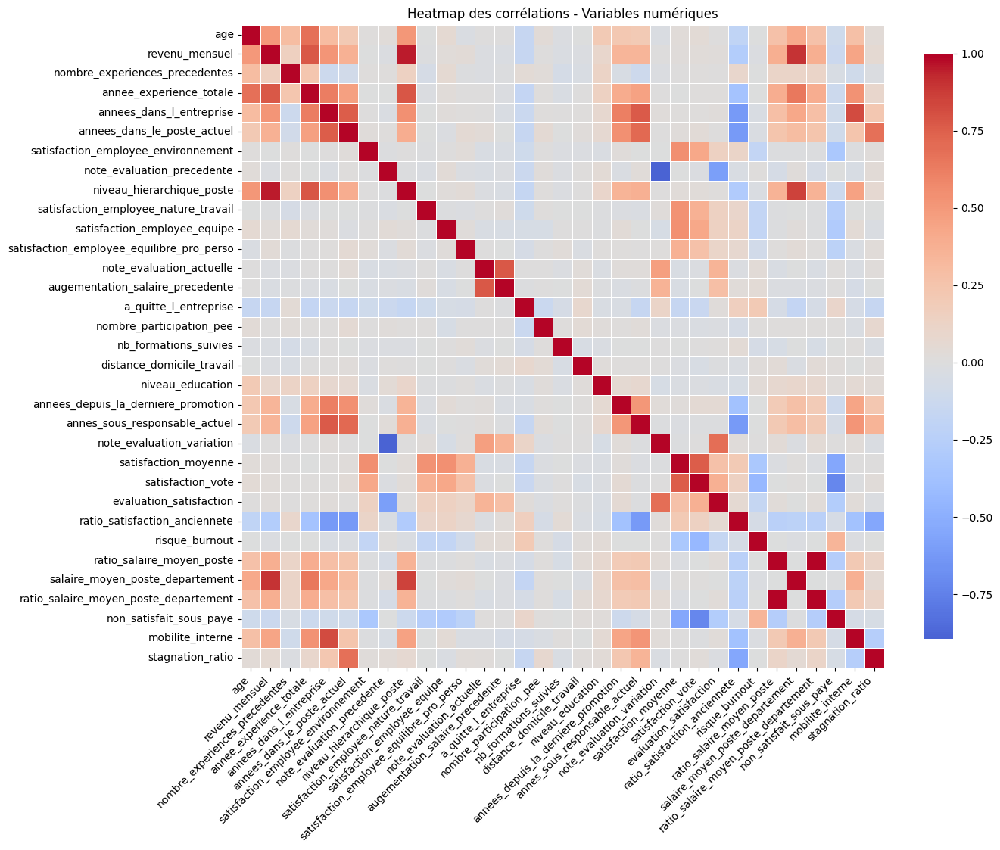

In [53]:
# sélection des features numériques en excluant le id_employee
num_features_exclure = ['id_employee',
                        'salaire_moyen_poste',
                        'salaire_moyen_poste']

data_employee['a_quitte_l_entreprise']= data_employee['a_quitte_l_entreprise'].map({'Non': 0,'Oui': 1})

num_features = [col for col in data_employee.select_dtypes(include=['int64','float64']).columns if col not in num_features_exclure] 
# calcul de la matrice de corrélation
corr_matrix = data_employee[num_features].corr(method='pearson')

# heatmap
plt.figure(figsize=(14, 12))

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)

plt.title('Heatmap des corrélations - Variables numériques')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'correlation_heatmap.png', dpi=300)
plt.show()

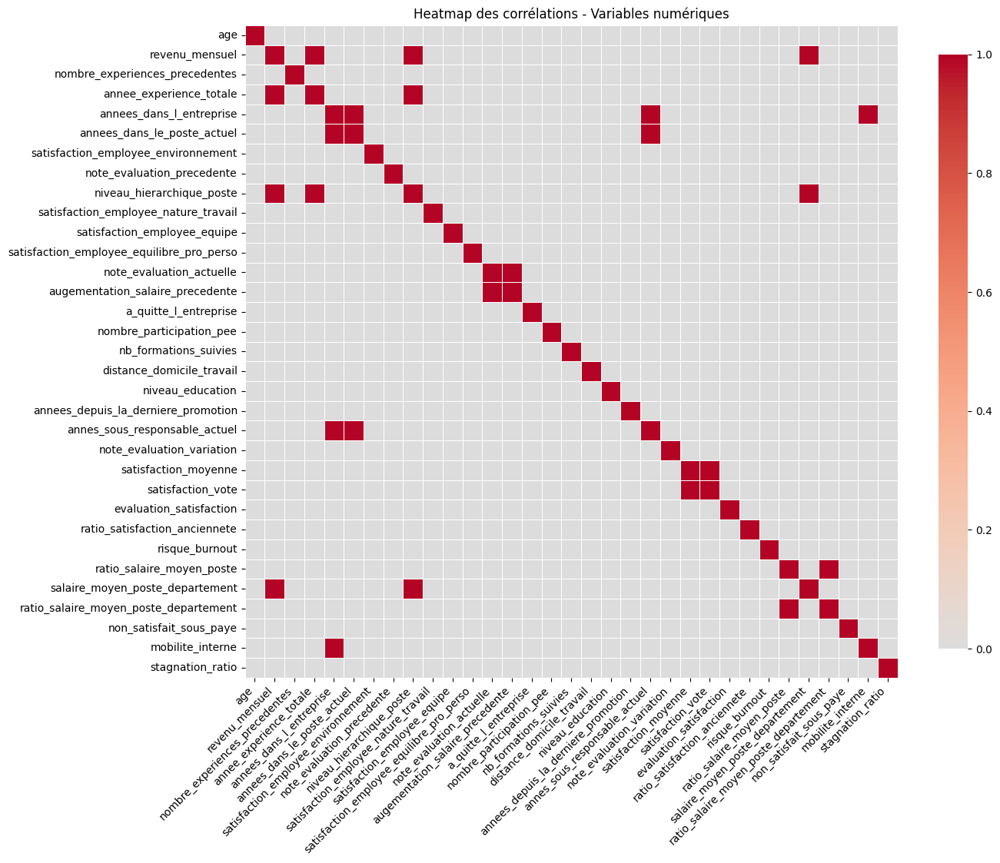

In [54]:
# heatmap : corrélation > 0.7
plt.figure(figsize=(14, 12))

sns.heatmap(
    corr_matrix>0.7,
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)

plt.title('Heatmap des corrélations - Variables numériques')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'correlation_heatmap_07.png', dpi=300)
plt.show()

Suppression des variables trop corrélées (|r| > 0,7) à une autre variable : `niveau_hierarchique_poste`, `annes_sous_responsable_actuel`, `satisfaction_vote`, `ratio_salaire_moyen_poste`, `note_evaluation_actuelle`. La heatmap ci-dessous vérifie qu'il ne reste plus de paire fortement corrélée.

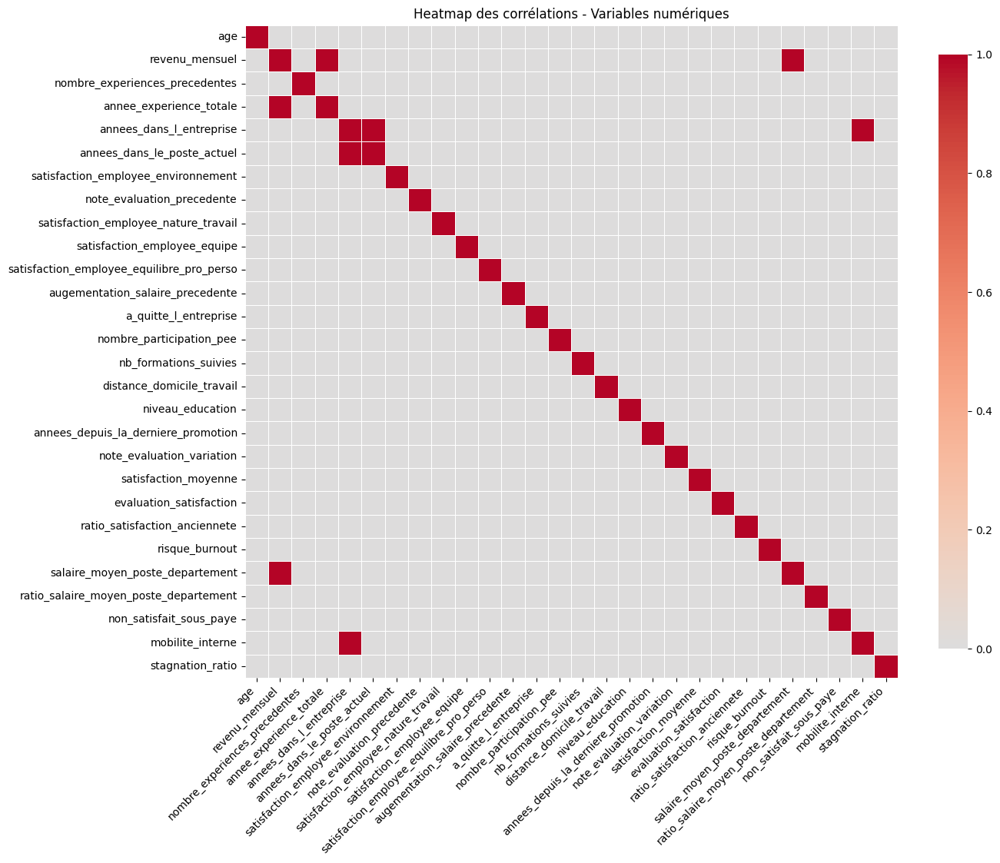

In [55]:
num_features_exclure_cor = ['niveau_hierarchique_poste',
                            'annes_sous_responsable_actuel',
                            'satisfaction_vote',
                            'ratio_salaire_moyen_poste',
                            'note_evaluation_actuelle']
                            #'mobilite_interne'
                            #'annees_dans_le_poste_actuel',
                            #'annee_experience_totale']

num_features = [col for col in num_features if col not in num_features_exclure_cor]

# calcul de la nouvelle matrice de corrélation - vérification
corr_matrix_verif = data_employee[num_features].corr(method='pearson')

# heatmap : corrélation > 0.7
plt.figure(figsize=(14, 12))

sns.heatmap(
    corr_matrix_verif>0.7,
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)

plt.title('Heatmap des corrélations - Variables numériques')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'correlation_heatmap_07_verif.png', dpi=300)
plt.show()

### 6.2 Corrélation de Spearman (relations monotones)

Contrôle complémentaire, robuste aux relations non linéaires monotones et aux valeurs extrêmes.

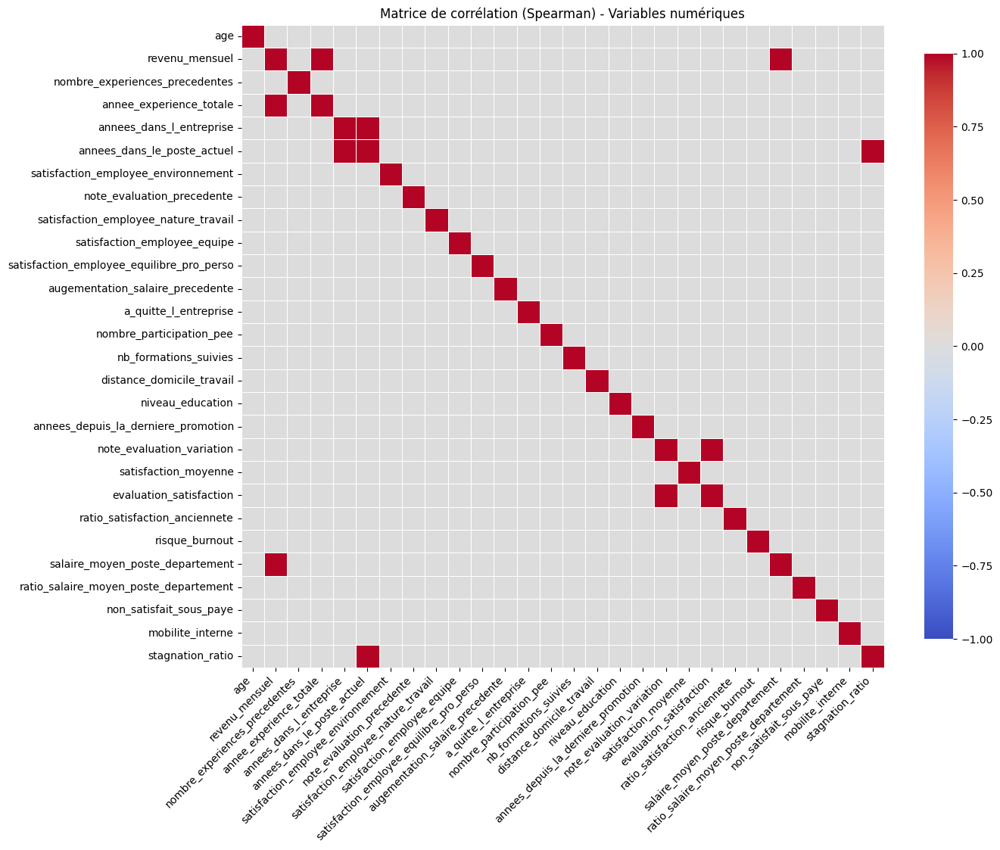

In [56]:
corr_spearman = data_employee[num_features].corr(method='spearman')

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr_spearman>0.7,
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8},
    vmin=-1, vmax=1
)

plt.title('Matrice de corrélation (Spearman) - Variables numériques')
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
#plt.savefig(FIGURES_DIR / 'spearman_corr_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

### 6.3 Pairplot

Recherche visuelle de relations non linéaires et de zones de séparation entre les deux classes.

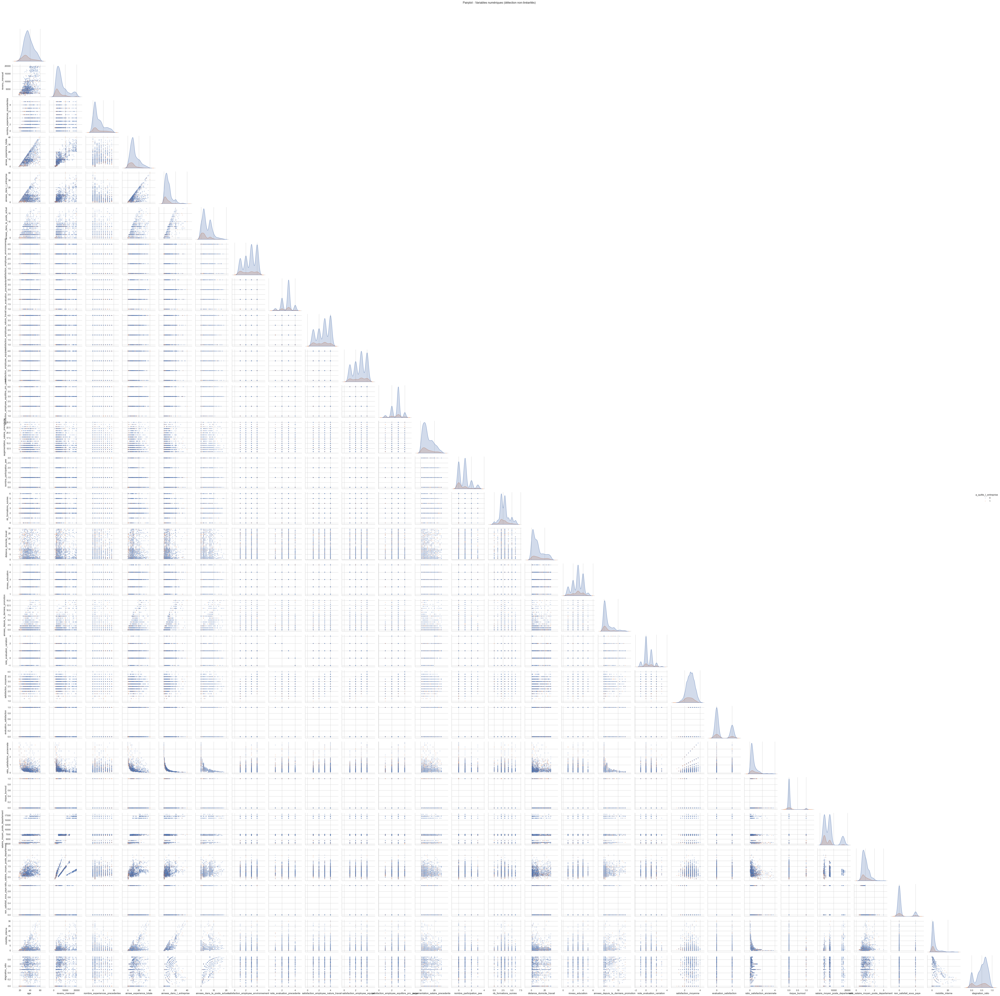

In [57]:
sns.set(style="whitegrid")

g = sns.pairplot(
    data_employee[num_features],
    hue='a_quitte_l_entreprise',
    diag_kind="kde",                 # diag = densité (plus lisible qu'un hist si assez de données)
    plot_kws={"alpha": 0.35, "s": 12, "edgecolor": "none"},
    corner=True                      # n'affiche que le triangle inférieur (plus léger)
)

g.fig.suptitle("Pairplot - Variables numériques (détection non-linéarités)", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pairplot_nonlinear.png", dpi=300, bbox_inches="tight")
plt.show()

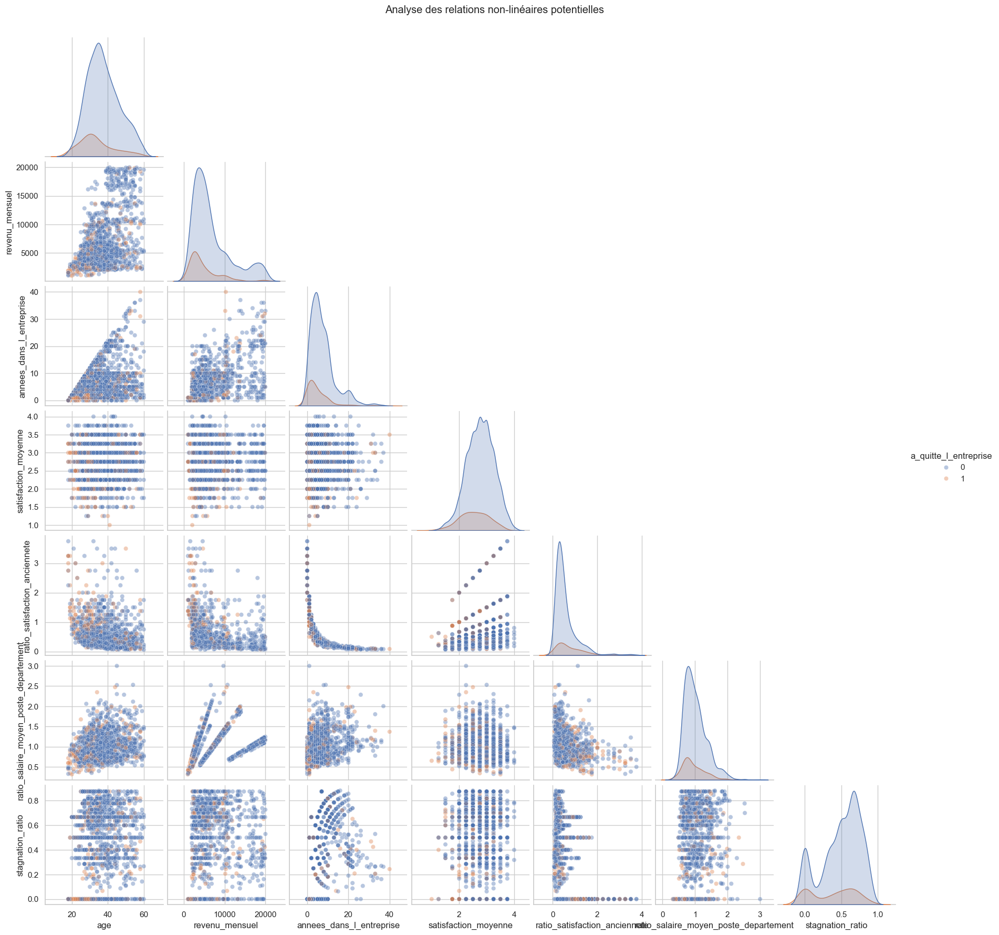

In [58]:
features_nonlinear = [
    'age',
    'revenu_mensuel',
    'annees_dans_l_entreprise',
    'satisfaction_moyenne',
    'ratio_satisfaction_anciennete',
    'ratio_salaire_moyen_poste_departement',
    'stagnation_ratio',
    'a_quitte_l_entreprise']

sns.pairplot(
    data_employee[features_nonlinear],
    hue='a_quitte_l_entreprise',
    diag_kind='kde',
    corner=True,
    plot_kws={'alpha':0.4}
)

plt.suptitle('Analyse des relations non-linéaires potentielles', y=1.02)
plt.savefig(FIGURES_DIR / 'pairplot_nonlinear_zoom.png', dpi=300, bbox_inches='tight')
plt.show()

> **Bilan de la sélection** : les variables redondantes sont écartées. Le pairplot montre un fort recouvrement des deux classes, sans frontière linéaire nette : cela justifie de tester un modèle non linéaire (XGBoost) en plus de la régression logistique.

## 7. Préparation des données pour la modélisation

### 7.1 Variables prédictives et cible

`X` = toutes les variables sauf l'identifiant, la cible et les variables redondantes identifiées en section 6 ; `y` = `a_quitte_l_entreprise` (1 = départ).

In [59]:
num_features_exclure_cor = ['niveau_hierarchique_poste',
                            'annes_sous_responsable_actuel',
                            'satisfaction_vote',
                            'ratio_salaire_moyen_poste',
                            'note_evaluation_actuelle']

X = data_employee.copy()
features = [col for col in X.columns if col not in ['id_employee','a_quitte_l_entreprise']+num_features_exclure_cor]
X= X[features]
X.head()

,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,satisfaction_employee_environnement,note_evaluation_precedente,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,heure_supplementaires,augementation_salaire_precedente,nombre_participation_pee,nb_formations_suivies,distance_domicile_travail,niveau_education,domaine_etude,frequence_deplacement,annees_depuis_la_derniere_promotion,note_evaluation_variation,satisfaction_moyenne,evaluation_satisfaction,ratio_satisfaction_anciennete,risque_burnout,salaire_moyen_poste,salaire_moyen_poste_departement,ratio_salaire_moyen_poste_departement,non_satisfait_sous_paye,mobilite_interne,stagnation_ratio
0,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,8,6,4,2,3,4,1,1,Oui,11,0,0,1,2,Infra & Cloud,Occasionnel,0,0,2.00,0,0.285714,1,6924.279141,6924.279141,0.865505,1,2,0.571429
1,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,10,10,7,3,2,2,4,3,Non,23,1,3,8,1,Infra & Cloud,Frequent,1,2,3.00,1,0.272727,0,3239.972603,3239.972603,1.583347,0,3,0.636364
2,37,M,2090,Célibataire,Consulting,Consultant,6,7,0,0,4,2,3,2,3,Oui,15,0,3,2,2,Autre,Occasionnel,0,1,3.00,1,3.000000,0,3237.169884,3237.169884,0.645626,0,0,0.000000
3,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,8,8,7,4,3,3,3,3,Oui,11,0,3,3,4,Infra & Cloud,Frequent,3,0,3.25,0,0.361111,0,3239.972603,3239.972603,0.897847,0,1,0.777778
4,27,M,3468,Marié(e),Consulting,Consultant,9,6,2,2,1,3,2,4,3,Non,12,1,3,2,1,Transformation Digitale,Occasionnel,2,0,2.50,0,0.833333,0,3237.169884,3237.169884,1.071306,0,0,0.666667


In [60]:
X.shape

(1470, 35)

In [61]:
y = data_employee['a_quitte_l_entreprise']
y

0       1
1       0
2       1
3       0
4       0
       ..
1465    0
1466    0
1467    0
1468    0
1469    0
Name: a_quitte_l_entreprise, Length: 1470, dtype: int64

### 7.2 Encodage des variables catégorielles

- **Binaire** : `heure_supplementaires` (Non/Oui → 0/1)
- **Ordinal** : `frequence_deplacement` (Aucun < Occasionnel < Fréquent → 0/1/2)
- **One-hot** : variables nominales sans ordre (genre, statut marital, département, poste, domaine d'étude)

In [62]:
cat_features = [col for col in X.select_dtypes(include=['str']).columns]
cat_features 

['genre',
 'statut_marital',
 'departement',
 'poste',
 'heure_supplementaires',
 'domaine_etude',
 'frequence_deplacement']

In [63]:
# Encodage binaire 
y= y.map({'Non': 0,'Oui': 1})

X['heure_supplementaires'] = X['heure_supplementaires'].map({'Non': 0,'Oui': 1})

# Encodage ordinal
X['frequence_deplacement'] = X['frequence_deplacement'].map({'Aucun': 0,'Occasionnel': 1,'Frequent': 2})

In [64]:
X

,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,satisfaction_employee_environnement,note_evaluation_precedente,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,heure_supplementaires,augementation_salaire_precedente,nombre_participation_pee,nb_formations_suivies,distance_domicile_travail,niveau_education,domaine_etude,frequence_deplacement,annees_depuis_la_derniere_promotion,note_evaluation_variation,satisfaction_moyenne,evaluation_satisfaction,ratio_satisfaction_anciennete,risque_burnout,salaire_moyen_poste,salaire_moyen_poste_departement,ratio_salaire_moyen_poste_departement,non_satisfait_sous_paye,mobilite_interne,stagnation_ratio
0,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,8,6,4,2,3,4,1,1,1,11,0,0,1,2,Infra & Cloud,1,0,0,2.00,0,0.285714,1,6924.279141,6924.279141,0.865505,1,2,0.571429
1,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,10,10,7,3,2,2,4,3,0,23,1,3,8,1,Infra & Cloud,2,1,2,3.00,1,0.272727,0,3239.972603,3239.972603,1.583347,0,3,0.636364
2,37,M,2090,Célibataire,Consulting,Consultant,6,7,0,0,4,2,3,2,3,1,15,0,3,2,2,Autre,1,0,1,3.00,1,3.000000,0,3237.169884,3237.169884,0.645626,0,0,0.000000
3,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,8,8,7,4,3,3,3,3,1,11,0,3,3,4,Infra & Cloud,2,3,0,3.25,0,0.361111,0,3239.972603,3239.972603,0.897847,0,1,0.777778
4,27,M,3468,Marié(e),Consulting,Consultant,9,6,2,2,1,3,2,4,3,0,12,1,3,2,1,Transformation Digitale,1,2,0,2.50,0,0.833333,0,3237.169884,3237.169884,1.071306,0,0,0.666667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,M,2571,Marié(e),Consulting,Consultant,4,17,5,2,3,4,4,3,3,0,17,1,3,23,2,Transformation Digitale,2,0,-1,3.25,0,0.541667,0,3237.169884,3237.169884,0.794212,0,3,0.333333
1466,39,M,9991,Marié(e),Consulting,Manager,4,9,7,7,4,2,1,1,3,0,15,1,5,6,1,Transformation Digitale,1,1,1,2.25,0,0.281250,0,7528.763359,7528.763359,1.327044,0,0,0.875000
1467,27,M,6142,Marié(e),Consulting,Tech Lead,1,6,6,2,2,4,2,2,3,1,20,1,0,4,3,Infra & Cloud,1,0,0,2.25,0,0.321429,1,7295.137931,7295.137931,0.841931,1,4,0.285714
1468,49,M,5390,Marié(e),Commercial,Cadre Commercial,2,17,9,6,4,2,2,4,2,0,14,0,3,2,3,Transformation Digitale,2,0,1,3.00,1,0.300000,0,6924.279141,6924.279141,0.778420,0,3,0.600000


In [65]:
y = data_employee['a_quitte_l_entreprise']
y

0       1
1       0
2       1
3       0
4       0
       ..
1465    0
1466    0
1467    0
1468    0
1469    0
Name: a_quitte_l_entreprise, Length: 1470, dtype: int64

#### Encodage one-hot des variables nominales

In [66]:
cat_features_onehot = ['genre',
                       'statut_marital',
                       'departement',
                       'poste',
                       'domaine_etude']

# initialisation 
enc_onehot = preprocessing.OneHotEncoder()

# onehot
X_enc_array = enc_onehot.fit_transform(X[cat_features_onehot]).toarray()

# noms de colonnes coherent avec le fit 
enc_onehot_columns = enc_onehot.get_feature_names_out(cat_features_onehot)

# reconstitustion du dataframe
X_enc = pd.DataFrame(X_enc_array, columns=enc_onehot_columns, index=X.index)

# suppression des colonnes catégorielles avant encodage
X = X.drop(columns=cat_features_onehot)

# remplacement par les colonnes (dataframe) encodées 
X = pd.concat([X, X_enc], axis=1)
X

,age,revenu_mensuel,nombre_experiences_precedentes,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,satisfaction_employee_environnement,note_evaluation_precedente,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,heure_supplementaires,augementation_salaire_precedente,nombre_participation_pee,nb_formations_suivies,distance_domicile_travail,niveau_education,frequence_deplacement,annees_depuis_la_derniere_promotion,note_evaluation_variation,satisfaction_moyenne,evaluation_satisfaction,ratio_satisfaction_anciennete,risque_burnout,salaire_moyen_poste,salaire_moyen_poste_departement,ratio_salaire_moyen_poste_departement,non_satisfait_sous_paye,mobilite_interne,stagnation_ratio,genre_F,genre_M,statut_marital_Célibataire,statut_marital_Divorcé(e),statut_marital_Marié(e),departement_Commercial,departement_Consulting,departement_Ressources Humaines,poste_Assistant de Direction,poste_Cadre Commercial,poste_Consultant,poste_Directeur Technique,poste_Manager,poste_Représentant Commercial,poste_Ressources Humaines,poste_Senior Manager,poste_Tech Lead,domaine_etude_Autre,domaine_etude_Entrepreunariat,domaine_etude_Infra & Cloud,domaine_etude_Marketing,domaine_etude_Ressources Humaines,domaine_etude_Transformation Digitale
0,41,5993,8,8,6,4,2,3,4,1,1,1,11,0,0,1,2,1,0,0,2.00,0,0.285714,1,6924.279141,6924.279141,0.865505,1,2,0.571429,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,49,5130,1,10,10,7,3,2,2,4,3,0,23,1,3,8,1,2,1,2,3.00,1,0.272727,0,3239.972603,3239.972603,1.583347,0,3,0.636364,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,37,2090,6,7,0,0,4,2,3,2,3,1,15,0,3,2,2,1,0,1,3.00,1,3.000000,0,3237.169884,3237.169884,0.645626,0,0,0.000000,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,33,2909,1,8,8,7,4,3,3,3,3,1,11,0,3,3,4,2,3,0,3.25,0,0.361111,0,3239.972603,3239.972603,0.897847,0,1,0.777778,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,27,3468,9,6,2,2,1,3,2,4,3,0,12,1,3,2,1,1,2,0,2.50,0,0.833333,0,3237.169884,3237.169884,1.071306,0,0,0.666667,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,2571,4,17,5,2,3,4,4,3,3,0,17,1,3,23,2,2,0,-1,3.25,0,0.541667,0,3237.169884,3237.169884,0.794212,0,3,0.333333,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1466,39,9991,4,9,7,7,4,2,1,1,3,0,15,1,5,6,1,1,1,1,2.25,0,0.281250,0,7528.763359,7528.763359,1.327044,0,0,0.875000,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1467,27,6142,1,6,6,2,2,4,2,2,3,1,20,1,0,4,3,1,0,0,2.25,0,0.321429,1,7295.137931,7295.137931,0.841931,1,4,0.285714,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1468,49,5390,2,17,9,6,4,2,2,4,2,0,14,0,3,2,3,2,0,1,3.00,1,0.300000,0,6924.279141,6924.279141,0.778420,0,3,0.600000,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


## 8. Modélisation

**Stratégie d'évaluation.** La cible est déséquilibrée (16 % de départs) : l'accuracy est trompeuse (87 % en prédisant « personne ne part »). On suit donc :
- le **rappel de la classe 1** : part des démissionnaires détectés (priorité métier) ;
- le **F2-score**, qui pondère le rappel 2 fois plus que la précision ;
- la **PR-AUC** (average precision), adaptée aux classes rares.

Démarche : baseline → modèle linéaire → modèle d'arbres, puis traitement du déséquilibre et réglage du seuil. Split train/test 80/20, `random_state = 42`.

In [67]:
X_encoded = X.copy()

num_features = X_encoded.columns

### 8.1 Baseline : DummyClassifier

Prédit toujours la classe majoritaire : c'est le **plancher** que tout modèle doit dépasser.

classification_report_train
              precision    recall  f1-score   support

           0       0.83      1.00      0.91       978
           1       0.00      0.00      0.00       198

    accuracy                           0.83      1176
   macro avg       0.42      0.50      0.45      1176
weighted avg       0.69      0.83      0.76      1176

classification_report_test
              precision    recall  f1-score   support

           0       0.87      1.00      0.93       255
           1       0.00      0.00      0.00        39

    accuracy                           0.87       294
   macro avg       0.43      0.50      0.46       294
weighted avg       0.75      0.87      0.81       294

ROC-AUC: 0.5
PR-AUC: 0.1326530612244898
{'model': DummyClassifier()}


C:\Users\fkhellad\Formation_IA\Projet4\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\fkhellad\Formation_IA\Projet4\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\fkhellad\Formation_IA\Projet4\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capi

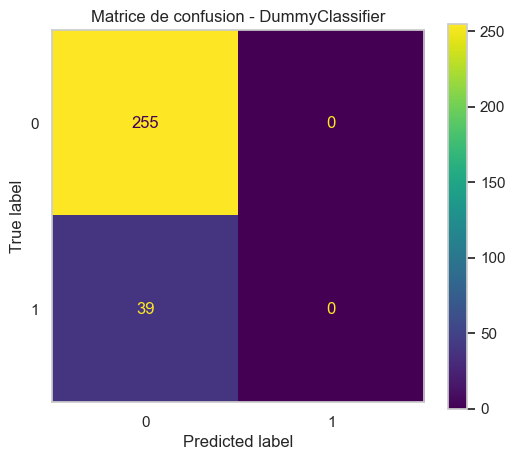

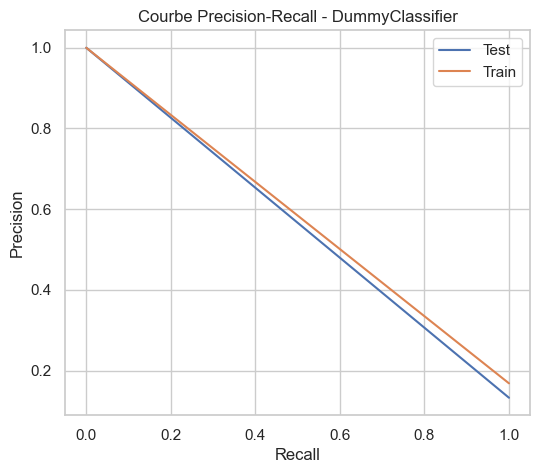

In [90]:
from sklearn.dummy import DummyClassifier

# préparation de données 
X_train, X_test, y_train, y_test,_,_ = prepare_data(X_encoded, 
                                                y,
                                                num_features=num_features,
                                                scale_X=False,
                                                scale_y=False,
                                                scaler_type="minmax",
                                                test_size= 0.2,
                                                random_state = 42)

# initialisation 
dummy_classifier = DummyClassifier()

# Entrainement - évaluation
results_dummy,_ = train_evaluate_model(dummy_classifier,
                                   X_train,
                                   X_test,
                                   y_train,
                                   y_test,
                                   scaler_y=None,
                                   plot=True,
                                   title = True)

print(results_dummy)

> **Résultat** : accuracy 87 % mais **rappel de 0** sur les départs ; PR-AUC 0,13 (= taux de départs). Cela confirme que l'accuracy n'est pas une métrique pertinente ici.

### 8.2 Modèle linéaire : régression logistique

Variables normalisées (MinMax), nécessaire pour un modèle linéaire.

classification_report_train
              precision    recall  f1-score   support

           0       0.91      0.98      0.94       978
           1       0.82      0.49      0.62       198

    accuracy                           0.90      1176
   macro avg       0.86      0.74      0.78      1176
weighted avg       0.89      0.90      0.89      1176

classification_report_test
              precision    recall  f1-score   support

           0       0.91      0.96      0.94       255
           1       0.62      0.38      0.48        39

    accuracy                           0.89       294
   macro avg       0.77      0.67      0.71       294
weighted avg       0.87      0.89      0.88       294

ROC-AUC: 0.6746606334841628
PR-AUC: 0.3220172684458399
{'model': LogisticRegression()}


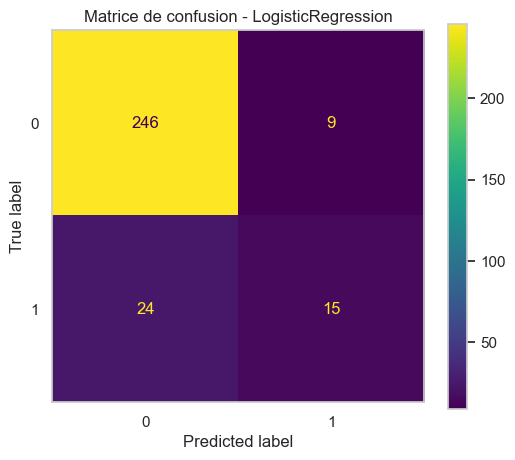

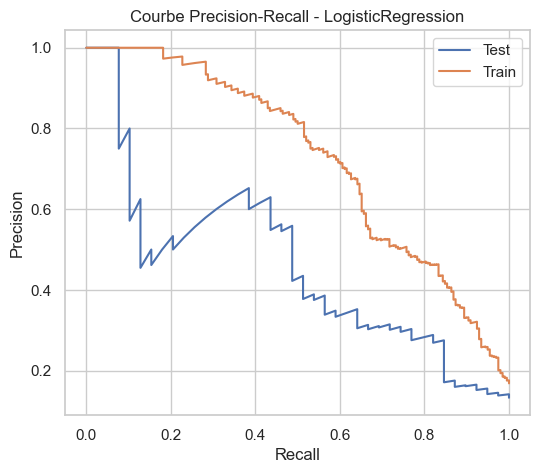

In [91]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_recall_curve, average_precision_score, PrecisionRecallDisplay, classification_report

# préparation de données 
X_train, X_test, y_train, y_test,_,_ = prepare_data(X_encoded, 
                                                y,
                                                num_features=num_features,
                                                scale_X=True,
                                                scale_y=False,
                                                scaler_type="minmax",
                                                test_size= 0.2,
                                                random_state = 42)

# initialisation 
logistic_regressor = LogisticRegression()

# Entrainement - évaluation
results_logreg,_ = train_evaluate_model(logistic_regressor,
                                   X_train,
                                   X_test,
                                   y_train,
                                   y_test,
                                   scaler_y=None,
                                   plot=True,
                                   title = True)

print(results_logreg)

> **Résultat** : nette amélioration (PR-AUC 0,32), mais **rappel de 0,38** seulement : 6 démissionnaires sur 10 ne sont pas détectés.

### 8.3 XGBoost (split simple)

Gradient boosting d'arbres, capable de capter les non-linéarités et interactions vues en EDA. Hyperparamètres optimisés en deux temps : **RandomizedSearchCV** (exploration large, 50 tirages), puis **GridSearchCV** local autour du meilleur point. Validation croisée à 5 folds, `refit` sur le F2.

In [92]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from sklearn.metrics import make_scorer, fbeta_score
from scipy.stats import randint, uniform
import numbers

# préparation de données 
X_train, X_test, y_train, y_test,_,_ = prepare_data(X_encoded, 
                                                y,
                                                num_features=num_features,
                                                scale_X=False,
                                                scale_y=False,
                                                scaler_type="minmax",
                                                test_size= 0.2,
                                                random_state = 42,
                                                stratify=None)

# paramètre à varier
parameters_highLevel_xgb = {
    "n_estimators": randint(300, 1200),
    "max_depth": randint(2, 10),
    "learning_rate": uniform(0.01, 0.19),     
    "subsample": uniform(0.6, 0.4),           
    "colsample_bytree": uniform(0.6, 0.4),   
    "min_child_weight": randint(1, 10),
    "reg_alpha": uniform(0.0, 1.0),
    "reg_lambda": uniform(0.5, 2.0)}



# initialisation 
XGBoost_classifier = XGBClassifier(objective="binary:logistic",
                                   random_state=42,
                                   n_jobs=-1)

#=========================================================================
# randomized Grid search
rSearch_xgb = RandomizedSearchCV(XGBoost_classifier, 
                                 param_distributions=parameters_highLevel_xgb, 
                                 cv = 5, 
                                 scoring={'PR-AUC': 'average_precision',
                                          'F2': make_scorer(fbeta_score, beta=2)}, 
                                 n_iter=50,
                                 random_state = 42,
                                 verbose = 1,
                                 refit='F2')
#=========================================================================
# train model
rSearch_xgb.fit(X_train, y_train)

print("Best params (RandomizedSearch):",rSearch_xgb.best_params_)
print("Best CV score:", rSearch_xgb.best_score_)

#=========================================================================
# best parameters & best model
best_params_xgb =rSearch_xgb.best_params_
best_model_xgb = rSearch_xgb.best_estimator_

#=========================================================================
# Construction d'une grille autour de best parameters 
xgb_param_grid = {}

for param, value in best_params_xgb.items():
    if isinstance(value, numbers.Integral):
        xgb_param_grid[param] = grid_around_best(value,2)
    else:
        # paramètres catégoriels (sqrt, log2, None, etc.)
        xgb_param_grid[param] = [value]
        
print("Grille autour de Best params (RandomizedSearch):",xgb_param_grid)

parameters_lowLevel_xgb = xgb_param_grid

#=========================================================================
# Grid search
gSearch_xgb = GridSearchCV(best_model_xgb, parameters_lowLevel_xgb, 
                   cv = 5, 
                   scoring={'PR-AUC': 'average_precision',
                            'F2': make_scorer(fbeta_score, beta=2)},
                   verbose = 1,
                   refit='F2')

#=========================================================================
# train model
gSearch_xgb.fit(X_train, y_train)
gSearch_xgb.best_params_



Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best params (RandomizedSearch): {'colsample_bytree': np.float64(0.8604308102007778), 'learning_rate': np.float64(0.18384233835331837), 'max_depth': 2, 'min_child_weight': 8, 'n_estimators': 1079, 'reg_alpha': np.float64(0.3308980248526492), 'reg_lambda': np.float64(0.6271167005720473), 'subsample': np.float64(0.7243929286862649)}
Best CV score: 0.4701996320056955
Grille autour de Best params (RandomizedSearch): {'colsample_bytree': [np.float64(0.8604308102007778)], 'learning_rate': [np.float64(0.18384233835331837)], 'max_depth': array([1, 2, 3, 4]), 'min_child_weight': array([ 6,  7,  8,  9, 10]), 'n_estimators': array([1077, 1078, 1079, 1080, 1081]), 'reg_alpha': [np.float64(0.3308980248526492)], 'reg_lambda': [np.float64(0.6271167005720473)], 'subsample': [np.float64(0.7243929286862649)]}
Fitting 5 folds for each of 100 candidates, totalling 500 fits


{'colsample_bytree': np.float64(0.8604308102007778),
 'learning_rate': np.float64(0.18384233835331837),
 'max_depth': np.int64(3),
 'min_child_weight': np.int64(8),
 'n_estimators': np.int64(1080),
 'reg_alpha': np.float64(0.3308980248526492),
 'reg_lambda': np.float64(0.6271167005720473),
 'subsample': np.float64(0.7243929286862649)}

classification_report_train
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       978
           1       1.00      0.99      0.99       198

    accuracy                           1.00      1176
   macro avg       1.00      0.99      1.00      1176
weighted avg       1.00      1.00      1.00      1176

classification_report_test
              precision    recall  f1-score   support

           0       0.89      0.93      0.91       255
           1       0.39      0.28      0.33        39

    accuracy                           0.85       294
   macro avg       0.64      0.61      0.62       294
weighted avg       0.83      0.85      0.84       294

ROC-AUC: 0.6076923076923076
PR-AUC: 0.20604395604395603
{'model': XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=np.float64(0.8604308102007778), device=None,
              early_stoppin

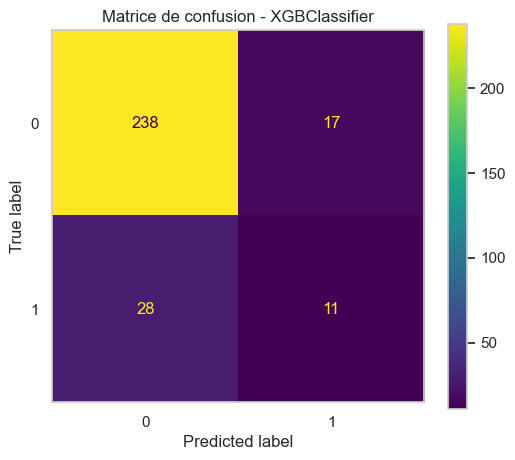

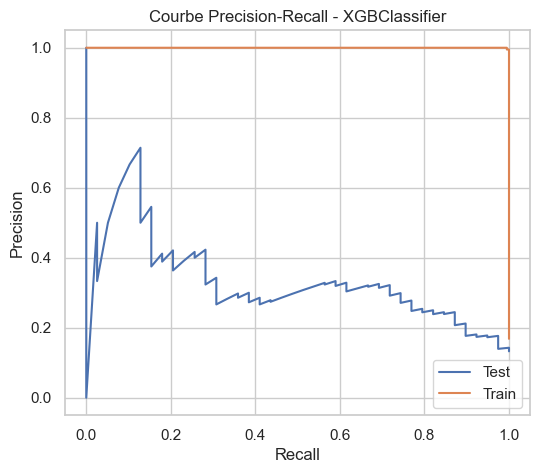

In [93]:
# nouveau best model
best_model_xgb = gSearch_xgb.best_estimator_
gSearch_xgb.best_score_

# Entrainement - évaluation
results_xgb,_ = train_evaluate_model(best_model_xgb,
                                   X_train,
                                   X_test,
                                   y_train,
                                   y_test,
                                   scaler_y=None,
                                   plot=True,
                                   title = True)

print(results_xgb)

> **Résultat** : **surapprentissage** marqué (scores parfaits en train, rappel de 0,28 en test). Sans traitement du déséquilibre, XGBoost ne fait pas mieux que la régression logistique.

### 8.4 XGBoost : split stratifié et pondération des classes (modèle retenu)

Deux corrections du déséquilibre :
- **split stratifié** : même proportion de départs dans le train et le test ;
- **pondération** : poids des démissionnaires = 2,5 × (nb restés / nb partis) via `sample_weight`.

In [94]:
# préparation de données 
f2_scorer = make_scorer(fbeta_score, beta=2)

X_train, X_test, y_train, y_test,_,_ = prepare_data(X_encoded, 
                                                y,
                                                num_features=num_features,
                                                scale_X=False,
                                                scale_y=False,
                                                scaler_type="minmax",
                                                test_size= 0.2,
                                                random_state = 42,
                                                stratify=y)

# paramètre à varier
parameters_highLevel_xgb = {
    "n_estimators": randint(300, 1200),
    "max_depth": randint(2, 10),
    "learning_rate": uniform(0.01, 0.19),     
    "subsample": uniform(0.6, 0.4),           
    "colsample_bytree": uniform(0.6, 0.4),   
    "min_child_weight": randint(1, 10),
    "reg_alpha": uniform(0.0, 1.0),
    "reg_lambda": uniform(0.5, 2.0)}



# initialisation 
XGBoost_classifier = XGBClassifier(objective="binary:logistic",
                                   random_state=42,
                                   n_jobs=-1)

#=========================================================================
# randomized Grid search
rSearch_xgb = RandomizedSearchCV(XGBoost_classifier, 
                                 param_distributions=parameters_highLevel_xgb, 
                                 cv = 5, 
                                 scoring={'PR-AUC': 'average_precision',
                                          'F2': make_scorer(fbeta_score, beta=2)}, 
                                 n_iter=50,
                                 random_state = 42,
                                 verbose = 1,
                                 refit='F2')
#=========================================================================
w_pos = 2.5*(y_train == 0).sum() / (y_train == 1).sum()
sample_weight_train = np.where(y_train == 1, w_pos, 1.0)

# train model
rSearch_xgb.fit(X_train, y_train,sample_weight=sample_weight_train)

print("Best params (RandomizedSearch):",rSearch_xgb.best_params_)
print("Best CV score:", rSearch_xgb.best_score_)

#=========================================================================
# best parameters & best model
best_params_xgb =rSearch_xgb.best_params_
best_model_xgb = rSearch_xgb.best_estimator_

#=========================================================================
# Construction d'une grille autour de best parameters 
xgb_param_grid = {}

for param, value in best_params_xgb.items():
    if isinstance(value, numbers.Integral):
        xgb_param_grid[param] = grid_around_best(value,2)
    else:
        # paramètres catégoriels (sqrt, log2, None, etc.)
        xgb_param_grid[param] = [value]
        
print("Grille autour de Best params (RandomizedSearch):",xgb_param_grid)

parameters_lowLevel_xgb = xgb_param_grid

#=========================================================================
# Grid search
gSearch_xgb = GridSearchCV(best_model_xgb, parameters_lowLevel_xgb, 
                   cv = 5, 
                   scoring={'PR-AUC': 'average_precision',
                            'F2': make_scorer(fbeta_score, beta=2)},
                   verbose = 1,
                   refit='F2')

#=========================================================================
# train model
gSearch_xgb.fit(X_train, y_train,sample_weight=sample_weight_train)
gSearch_xgb.best_params_

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best params (RandomizedSearch): {'colsample_bytree': np.float64(0.763581177765708), 'learning_rate': np.float64(0.0429259208134607), 'max_depth': 2, 'min_child_weight': 2, 'n_estimators': 395, 'reg_alpha': np.float64(0.5492266647061205), 'reg_lambda': np.float64(1.9291918454001247), 'subsample': np.float64(0.8640789506870925)}
Best CV score: 0.7332788778134213
Grille autour de Best params (RandomizedSearch): {'colsample_bytree': [np.float64(0.763581177765708)], 'learning_rate': [np.float64(0.0429259208134607)], 'max_depth': array([1, 2, 3, 4]), 'min_child_weight': array([1, 2, 3, 4]), 'n_estimators': array([393, 394, 395, 396, 397]), 'reg_alpha': [np.float64(0.5492266647061205)], 'reg_lambda': [np.float64(1.9291918454001247)], 'subsample': [np.float64(0.8640789506870925)]}
Fitting 5 folds for each of 80 candidates, totalling 400 fits


{'colsample_bytree': np.float64(0.763581177765708),
 'learning_rate': np.float64(0.0429259208134607),
 'max_depth': np.int64(1),
 'min_child_weight': np.int64(1),
 'n_estimators': np.int64(395),
 'reg_alpha': np.float64(0.5492266647061205),
 'reg_lambda': np.float64(1.9291918454001247),
 'subsample': np.float64(0.8640789506870925)}

classification_report_train
              precision    recall  f1-score   support

           0       0.98      0.51      0.67       986
           1       0.27      0.96      0.43       190

    accuracy                           0.58      1176
   macro avg       0.63      0.73      0.55      1176
weighted avg       0.87      0.58      0.63      1176

classification_report_test
              precision    recall  f1-score   support

           0       0.95      0.48      0.64       247
           1       0.24      0.87      0.38        47

    accuracy                           0.54       294
   macro avg       0.60      0.68      0.51       294
weighted avg       0.84      0.54      0.59       294

ROC-AUC: 0.675036609527091
PR-AUC: 0.23079614824653266
{'model': XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=np.float64(0.763581177765708), device=None,
              early_stopping_

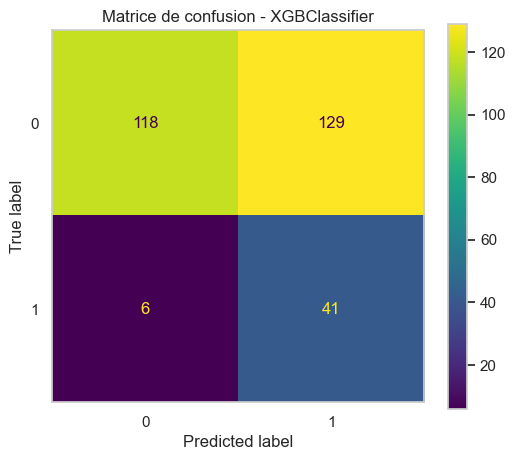

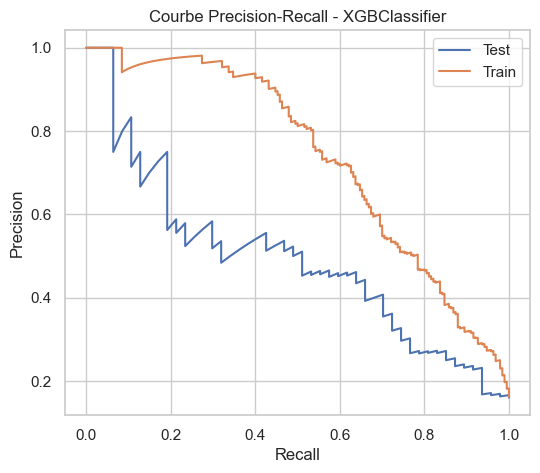

In [95]:
# nouveau best model
best_model_xgb = gSearch_xgb.best_estimator_
gSearch_xgb.best_score_

# Entrainement - évaluation
results_xgb,_ = train_evaluate_model(best_model_xgb,
                                   X_train,
                                   X_test,
                                   y_train,
                                   y_test,
                                   scaler_y=None,
                                   plot=True,
                                   title = True,
                                   sample_weights = sample_weight_train)

print(results_xgb)

Avec le seuil par défaut (0,5), le rappel grimpe à **0,87** mais la précision chute à 0,24 (trop de fausses alertes).

#### Optimisation du seuil de décision

Le seuil est choisi pour **maximiser le F2** sur la courbe précision-rappel, afin de trouver un meilleur compromis rappel/précision.

In [130]:
from sklearn.metrics import precision_recall_curve

# calcul de probabilités
y_proba = best_model_xgb.predict_proba(X_test)[:,1]

precision, recall, thresholds = precision_recall_curve(y_test, y_proba)

# calcul de F2
beta = 2
F2 = ((1+beta**2)*precision*recall)/((beta**2)*precision+recall)

best_idx = np.argmax(F2)
best_threshold = thresholds[best_idx]

print("Seuil optimal F2 :", best_threshold)
print("F2 max :", F2[best_idx])

Seuil optimal F2 : 0.71092564
F2 max : 0.6133828996282527


In [131]:
y_pred_opt = (y_proba >= best_threshold).astype(int)
print(classification_report(y_test, y_pred_opt))

              precision    recall  f1-score   support

           0       0.93      0.81      0.87       247
           1       0.41      0.70      0.52        47

    accuracy                           0.79       294
   macro avg       0.67      0.75      0.69       294
weighted avg       0.85      0.79      0.81       294



> **Résultat (seuil optimisé ≈ 0,71)** : **rappel 0,70**, précision 0,41, F1 0,52, F2 0,61. Le modèle détecte **7 démissionnaires sur 10** avec un niveau de fausses alertes acceptable pour un usage RH (entretien préventif).

#### Sauvegarde du modèle retenu

Le modèle est enregistré dans `models/` au **format natif XGBoost** (JSON), portable d'une version à l'autre, contrairement à pickle. Le **seuil de décision optimisé** et la liste ordonnée des variables sont stockés à part : sans eux, le modèle reprendrait le seuil par défaut (0,5).

Rechargement :
```python
model = XGBClassifier()
model.load_model(MODELS_DIR / "xgb_attrition.json")
meta = json.load(open(MODELS_DIR / "xgb_attrition_metadata.json", encoding="utf-8"))
y_pred = (model.predict_proba(X[meta["features"]])[:, 1] >= meta["decision_threshold"]).astype(int)
```

In [ ]:
import json
import xgboost

# modèle au format natif XGBoost (portable entre versions, contrairement à pickle)
model_path = MODELS_DIR / "xgb_attrition.json"
best_model_xgb.save_model(str(model_path))

# métadonnées nécessaires à l'inférence : seuil optimisé (F2) et ordre des variables
metadata = {
    "model_file": model_path.name,
    "decision_threshold": float(best_threshold),
    "optimized_metric": "F2",
    "features": list(X_train.columns),
    "xgboost_version": xgboost.__version__,
}
metadata_path = MODELS_DIR / "xgb_attrition_metadata.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print(f"Modèle      : {model_path}")
print(f"Métadonnées : {metadata_path} (seuil = {best_threshold:.3f})")

### 8.5 Variante testée : `scale_pos_weight` (non retenue)

Variante avec le paramètre natif `scale_pos_weight` d'XGBoost et un poids plus faible (1,5×). **Le code est commenté** : les sorties affichées proviennent d'une exécution antérieure, conservées pour comparaison.

In [67]:
# from collections import Counter

# # préparation de données 
# f2_scorer = make_scorer(fbeta_score, beta=2)

# X_train, X_test, y_train, y_test,_,_ = prepare_data(X_encoded, 
#                                                 y,
#                                                 num_features=num_features,
#                                                 scale_X=False,
#                                                 scale_y=False,
#                                                 scaler_type="minmax",
#                                                 test_size= 0.2,
#                                                 random_state = 42,
#                                                 stratify=y)

# # paramètre à varier
# parameters_highLevel_xgb = {
#     "n_estimators": randint(300, 1200),
#     "max_depth": randint(2, 10),
#     "learning_rate": uniform(0.01, 0.19),     
#     "subsample": uniform(0.6, 0.4),           
#     "colsample_bytree": uniform(0.6, 0.4),   
#     "min_child_weight": randint(1, 10),
#     "reg_alpha": uniform(0.0, 1.0),
#     "reg_lambda": uniform(0.5, 2.0)}

# # calcul du ratio scale_pos_weight
# counter = Counter(y_train)
# scale_pos_weight = counter[0] / counter[1]
# print("scale_pos_weight:", scale_pos_weight)


# # initialisation 
# XGBoost_classifier = XGBClassifier(objective="binary:logistic",
#                                    random_state=42,
#                                    n_jobs=-1,
#                                    scale_pos_weight=scale_pos_weight)

# #=========================================================================
# # randomized Grid search
# rSearch_xgb = RandomizedSearchCV(XGBoost_classifier, 
#                                  param_distributions=parameters_highLevel_xgb, 
#                                  cv = 5, 
#                                  scoring={'PR-AUC': 'average_precision',
#                                           'F2': make_scorer(fbeta_score, beta=2)}, 
#                                  n_iter=50,
#                                  random_state = 42,
#                                  verbose = 1,
#                                  refit='F2')
# #=========================================================================
# w_pos = 1.5*(y_train == 0).sum() / (y_train == 1).sum()
# sample_weight_train = np.where(y_train == 1, w_pos, 1.0)

# # train model
# # rSearch_xgb.fit(X_train, y_train,sample_weight=sample_weight_train)
# rSearch_xgb.fit(X_train, y_train)

# print("Best params (RandomizedSearch):",rSearch_xgb.best_params_)
# print("Best CV score:", rSearch_xgb.best_score_)

# #=========================================================================
# # best parameters & best model
# best_params_xgb =rSearch_xgb.best_params_
# best_model_xgb = rSearch_xgb.best_estimator_

# #=========================================================================
# # Construction d'une grille autour de best parameters 
# xgb_param_grid = {}

# for param, value in best_params_xgb.items():
#     if isinstance(value, numbers.Integral):
#         xgb_param_grid[param] = grid_around_best(value,2)
#     else:
#         # paramètres catégoriels (sqrt, log2, None, etc.)
#         xgb_param_grid[param] = [value]
        
# print("Grille autour de Best params (RandomizedSearch):",xgb_param_grid)

# parameters_lowLevel_xgb = xgb_param_grid

# #=========================================================================
# # Grid search
# gSearch_xgb = GridSearchCV(best_model_xgb, parameters_lowLevel_xgb, 
#                    cv = 5, 
#                    scoring={'PR-AUC': 'average_precision',
#                             'F2': make_scorer(fbeta_score, beta=2)},
#                    verbose = 1,
#                    refit='F2')

# #=========================================================================
# # train model
# # gSearch_xgb.fit(X_train, y_train,sample_weight=sample_weight_train)
# gSearch_xgb.fit(X_train, y_train)
# gSearch_xgb.best_params_

scale_pos_weight: 5.189473684210526
Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best params (RandomizedSearch): {'colsample_bytree': np.float64(0.763581177765708), 'learning_rate': np.float64(0.0429259208134607), 'max_depth': 2, 'min_child_weight': 2, 'n_estimators': 395, 'reg_alpha': np.float64(0.5492266647061205), 'reg_lambda': np.float64(1.9291918454001247), 'subsample': np.float64(0.8640789506870925)}
Best CV score: 0.588789611921318
Grille autour de Best params (RandomizedSearch): {'colsample_bytree': [np.float64(0.763581177765708)], 'learning_rate': [np.float64(0.0429259208134607)], 'max_depth': array([1, 2, 3, 4]), 'min_child_weight': array([1, 2, 3, 4]), 'n_estimators': array([393, 394, 395, 396, 397]), 'reg_alpha': [np.float64(0.5492266647061205)], 'reg_lambda': [np.float64(1.9291918454001247)], 'subsample': [np.float64(0.8640789506870925)]}
Fitting 5 folds for each of 80 candidates, totalling 400 fits


{'colsample_bytree': np.float64(0.763581177765708),
 'learning_rate': np.float64(0.0429259208134607),
 'max_depth': np.int64(1),
 'min_child_weight': np.int64(1),
 'n_estimators': np.int64(394),
 'reg_alpha': np.float64(0.5492266647061205),
 'reg_lambda': np.float64(1.9291918454001247),
 'subsample': np.float64(0.8640789506870925)}

classification_report_train
              precision    recall  f1-score   support

           0       1.00      0.18      0.31       986
           1       0.19      1.00      0.32       190

    accuracy                           0.32      1176
   macro avg       0.60      0.59      0.32      1176
weighted avg       0.87      0.32      0.31      1176

classification_report_test
              precision    recall  f1-score   support

           0       0.94      0.18      0.31       247
           1       0.18      0.94      0.30        47

    accuracy                           0.30       294
   macro avg       0.56      0.56      0.30       294
weighted avg       0.82      0.30      0.30       294

ROC-AUC: 0.5591782237918856
PR-AUC: 0.17764916033875927
{'model': XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=np.float64(0.763581177765708), device=None,
              early_stopping

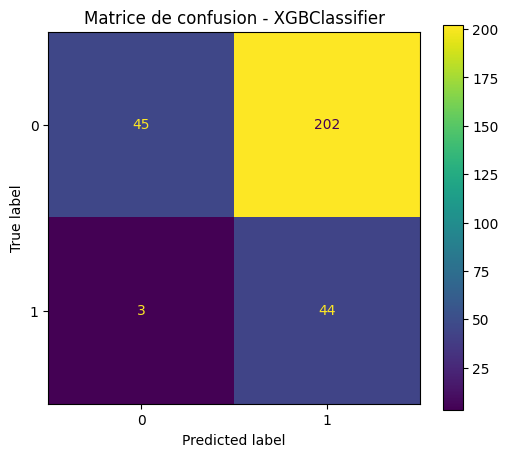

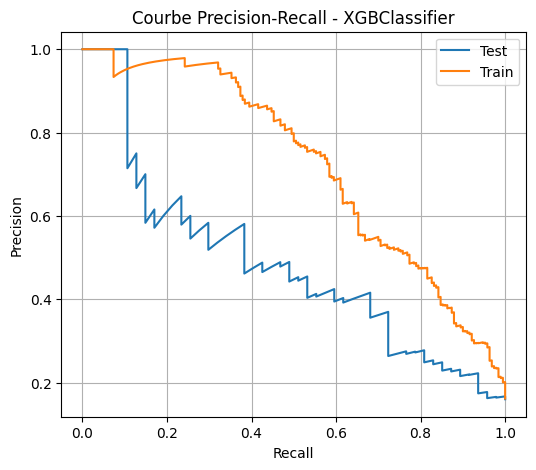

In [68]:
# # nouveau best model
# best_model_xgb = gSearch_xgb.best_estimator_
# gSearch_xgb.best_score_

# # Entrainement - évaluation
# results_xgb,_ = train_evaluate_model(best_model_xgb,
#                                    X_train,
#                                    X_test,
#                                    y_train,
#                                    y_test,
#                                    scaler_y=None,
#                                    plot=True,
#                                    title = True,
#                                    sample_weights = sample_weight_train)

# print(results_xgb)

In [69]:
# from sklearn.metrics import precision_recall_curve

# y_proba = best_model_xgb.predict_proba(X_test)[:,1]

# precision, recall, thresholds = precision_recall_curve(y_test, y_proba)

# # calcul de F2
# beta = 2
# F2 = ((1+beta**2)*precision*recall)/((beta**2)*precision+recall)

# best_idx = np.argmax(F2)
# best_threshold = thresholds[best_idx]

# print("Seuil optimal F2 :", best_threshold)
# print("F2 max :", F2[best_idx])
# y_pred_opt = (y_proba >= best_threshold).astype(int)
# print(classification_report(y_test, y_pred_opt))

Seuil optimal F2 : 0.86095977
F2 max : 0.6071428571428572
              precision    recall  f1-score   support

           0       0.94      0.77      0.84       247
           1       0.37      0.72      0.49        47

    accuracy                           0.76       294
   macro avg       0.65      0.74      0.67       294
weighted avg       0.85      0.76      0.79       294



> **Résultat** : performances proches mais légèrement inférieures (rappel 0,72, précision 0,37, F1 0,49), avec un seuil très élevé (0,86) signe d'une sur-pondération. La version 8.4 est conservée.

### Synthèse de la modélisation (classe « départ », jeu de test)

| Modèle | Précision | Rappel | F1 |
|---|---|---|---|
| Dummy | 0,00 | 0,00 | 0,00 |
| Régression logistique | 0,62 | 0,38 | 0,48 |
| XGBoost (split simple) | 0,39 | 0,28 | 0,33 |
| **XGBoost stratifié + pondéré + seuil F2** | **0,41** | **0,70** | **0,52** |

## 9. Interprétabilité du modèle

Trois approches complémentaires, du plus simple au plus fiable :
1. **Importance native XGBoost** : rapide, mais biaisée vers les variables très utilisées dans les splits.
2. **Permutation importance** : perte de PR-AUC quand on mélange une variable, mesurée sur le test.
3. **SHAP** : contribution de chaque variable à chaque prédiction (global **et** local), avec le sens de l'effet.

In [96]:
from sklearn.inspection import permutation_importance
import shap
feature = X_train.columns

### 9.1 Importance native XGBoost

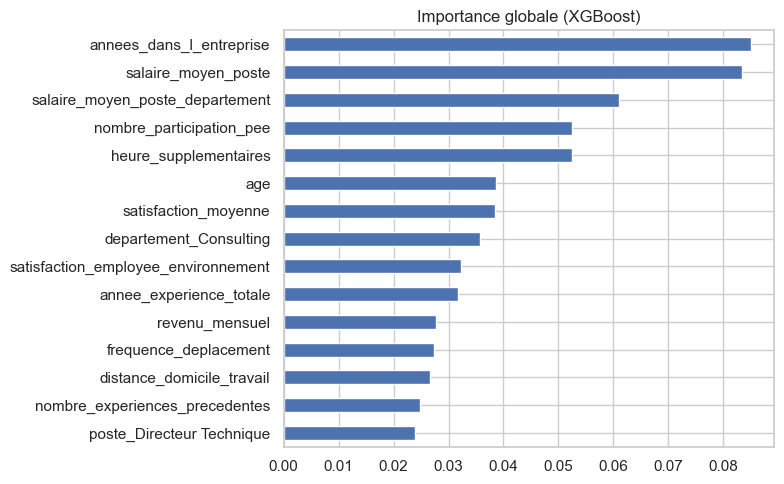

In [98]:
# ============================================
# Importance globale avec feature_importances  
imp = pd.Series(best_model_xgb.feature_importances_, index=feature).sort_values(ascending=False)

plt.figure(figsize=(8,5))
imp.head(15).sort_values().plot(kind="barh")
plt.title("Importance globale (XGBoost)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'feature_importances.png', dpi=300)
plt.show()

### 9.2 Permutation importance (PR-AUC, jeu de test)

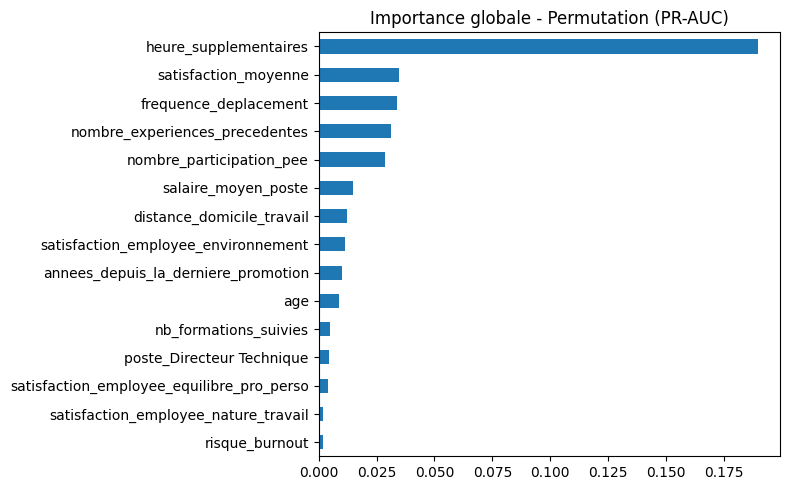

In [104]:
# ============================================
# Importance globale avec permutation importance  
perm = permutation_importance(best_model_xgb, X_test, y_test, n_repeats=10, random_state=42,scoring='average_precision')

imp_perm = pd.Series(perm.importances_mean, index=feature).sort_values(ascending=False)

plt.figure(figsize=(8,5))
imp_perm.head(15).sort_values().plot(kind="barh")
plt.title("Importance globale - Permutation (PR-AUC)")
plt.tight_layout()
plt.show()

### 9.3 SHAP : importance globale

Calcul sur un échantillon de 200 employés du test. Lecture du beeswarm : chaque point est un employé ; à **droite**, la variable **augmente** la probabilité de départ ; la couleur indique la valeur de la variable (rouge = élevée).

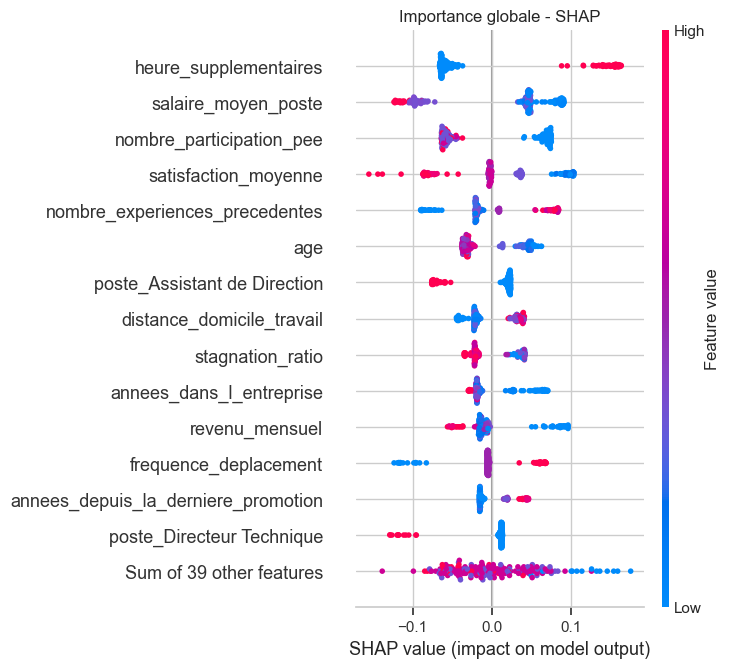

In [108]:
# ============================================
# SHAP (global) -> Beeswarm Modèle à base d'arbres => TreeExplainer 
import shap

fig = plt.figure(figsize=(25,6))

X_shap = X_test.sample(min(200, len(X_test)), random_state=42)

# fonction callable -> proba classe 1
f = lambda X: best_model_xgb.predict_proba(X)[:, 1]

explainer = shap.Explainer(f, X_shap)   # masker = X_shap
shap_values = explainer(X_shap)

shap.plots.beeswarm(shap_values, max_display=15, show=False)
fig = plt.gcf()
plt.subplots_adjust(left=0.45)
plt.title("Importance globale - SHAP")
plt.savefig(FIGURES_DIR / 'feature_importance_SHAP_global_explainer.png', dpi=300)
plt.show()

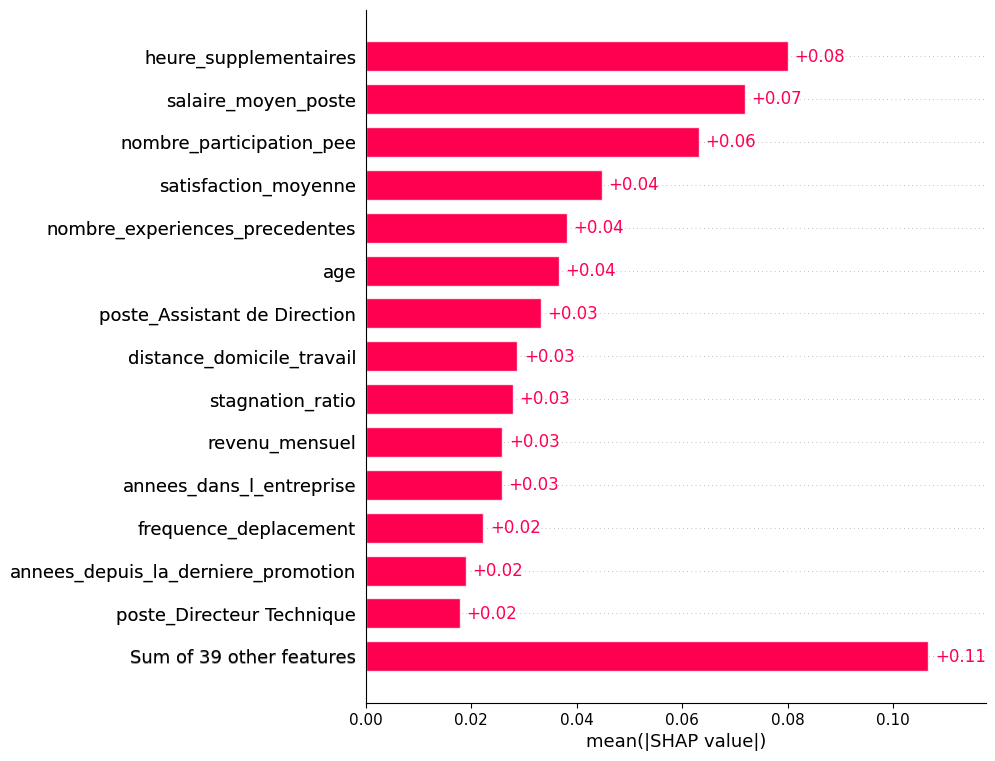

In [112]:
shap.plots.bar(shap_values, max_display=15)

> **Lecture SHAP globale**
> - **Heures supplémentaires** : premier facteur ; en faire augmente fortement le risque.
> - **Rémunération** (salaire moyen du poste, revenu) : les postes et salaires faibles poussent au départ.
> - **Faible participation au PEE** et **satisfaction moyenne basse** : marqueurs de désengagement.
> - **Nombreuses expériences précédentes**, **jeune âge**, **distance domicile-travail** et **déplacements fréquents** augmentent le risque.
> - Une **ancienneté** élevée et les postes à responsabilité (Directeur technique) protègent.

### 9.4 SHAP : explications locales

Décomposition de prédictions individuelles (2 employés restés, 2 partis) : waterfall puis force plots, avec un zoom sur les 4 variables les plus influentes.

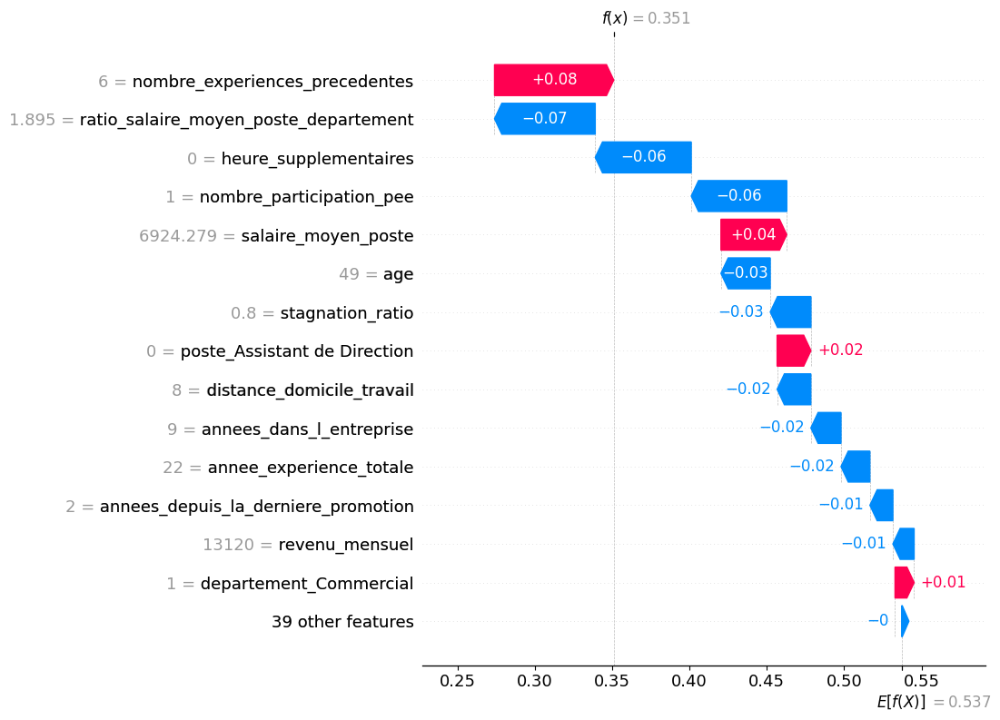

In [111]:
shap.plots.waterfall(shap_values[0], max_display=15)

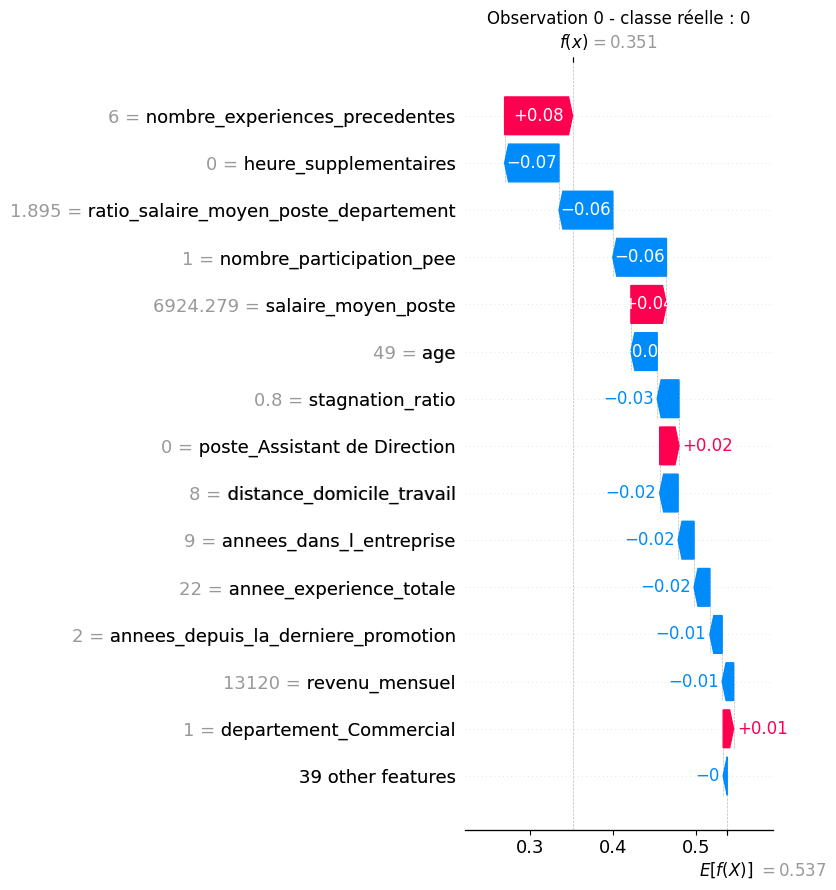

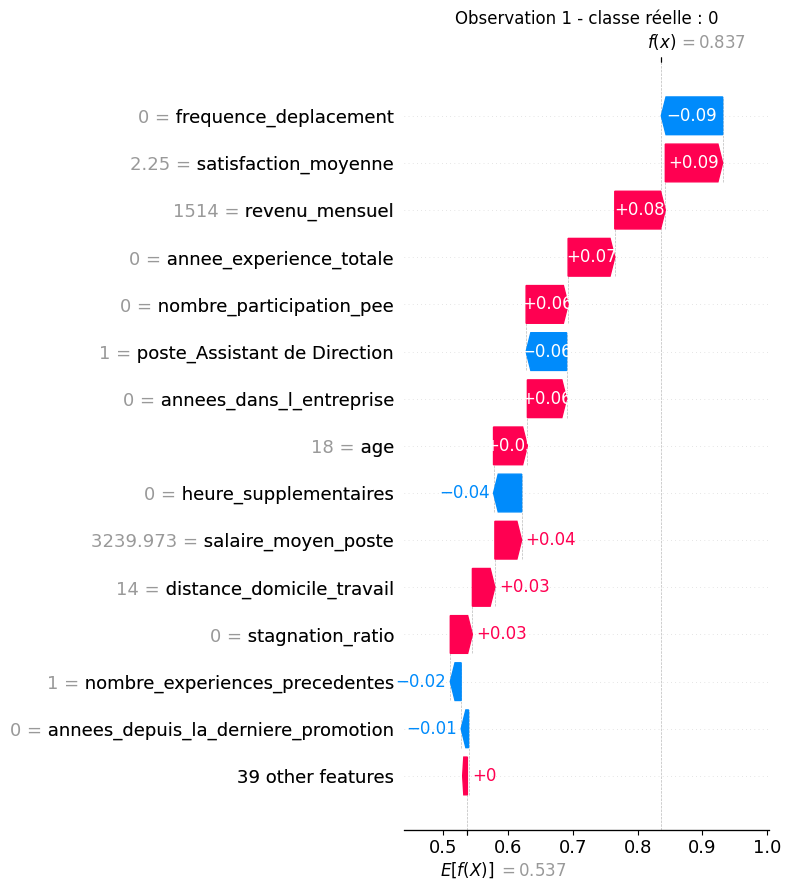

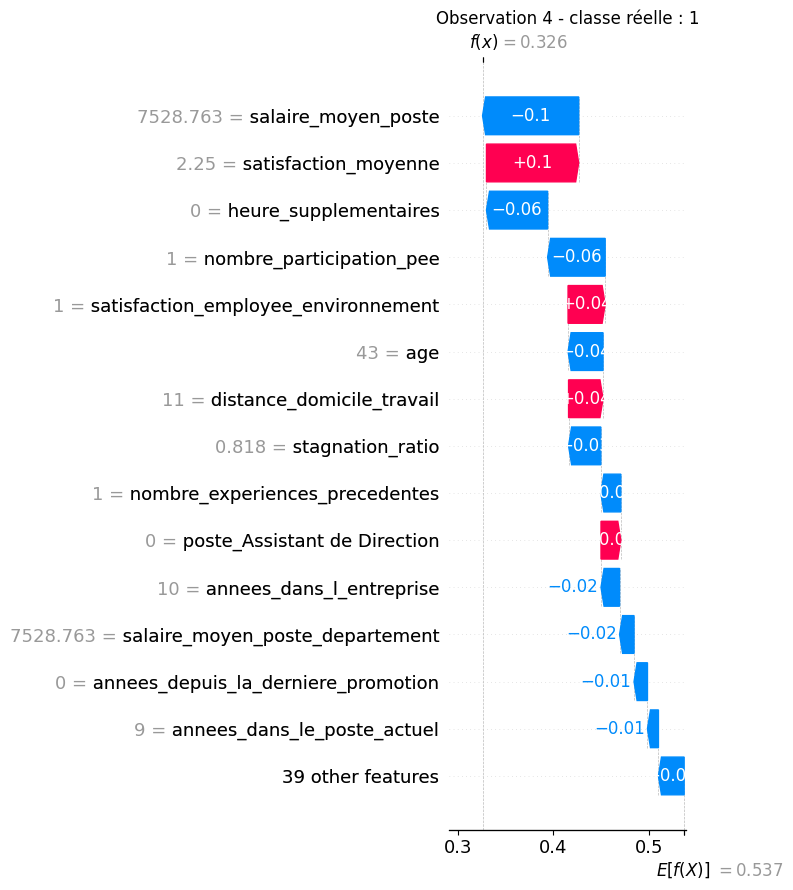

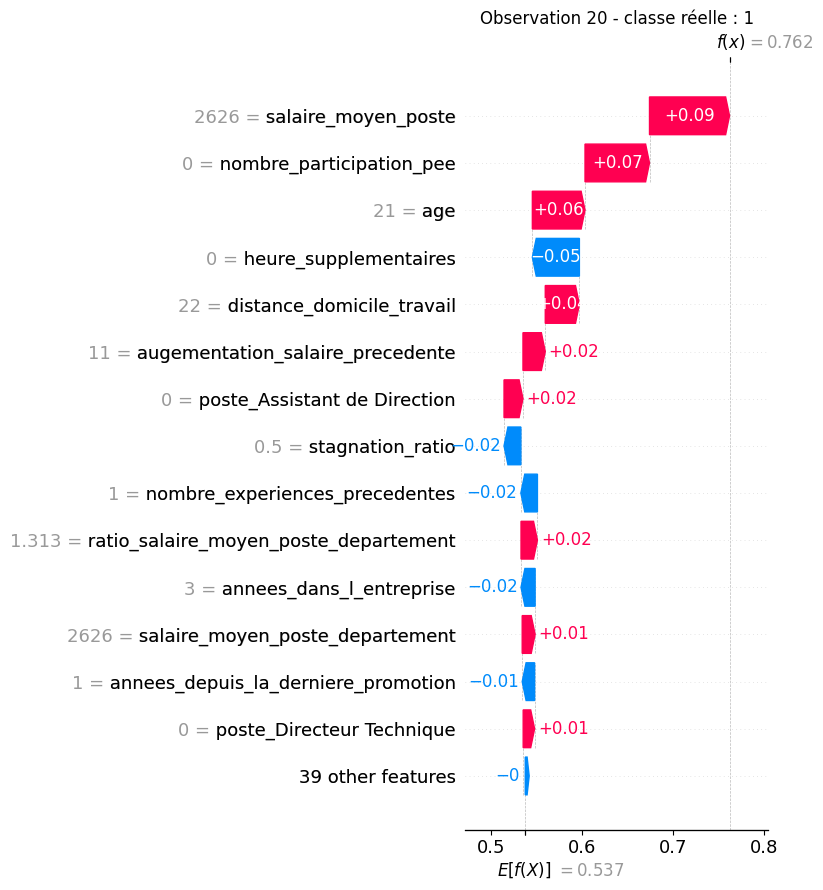

In [134]:
# affichage des importances locales avec waterfall_plot : 2 observations de chaque classe
# indices des deux classes
idx_0 = np.where(y_test == 0)[0][:2]
idx_1 = np.where(y_test == 1)[0][:2]

indices = list(idx_0) + list(idx_1)

for i in indices:
    #print(f"Observation {i} - classe réelle : {y_test[i]}")
    plt.figure(figsize=(20,5))
    # shap.plots.waterfall(shap_values[i], max_display=10)
    shap.waterfall_plot(shap_values[i], max_display=15, show=False)
    plt.title(f'Observation {i} - classe réelle : {y_test[i]}')
    #fig.set_size_inches(8,5)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f'shap_waterfall_obs_{i}.png', dpi=300)
    plt.show()
    plt.close()

<Figure size 2000x300 with 0 Axes>

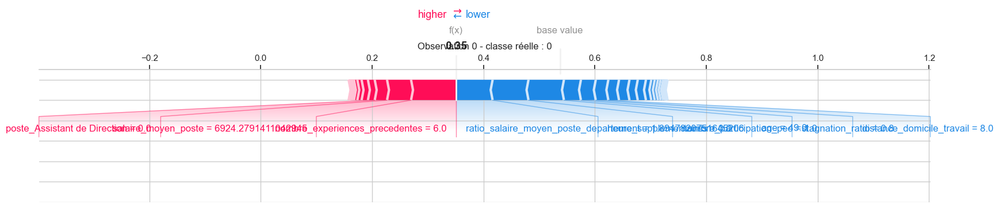

<Figure size 2000x300 with 0 Axes>

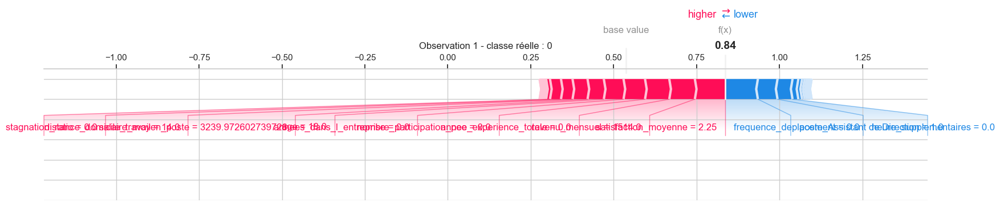

<Figure size 2000x300 with 0 Axes>

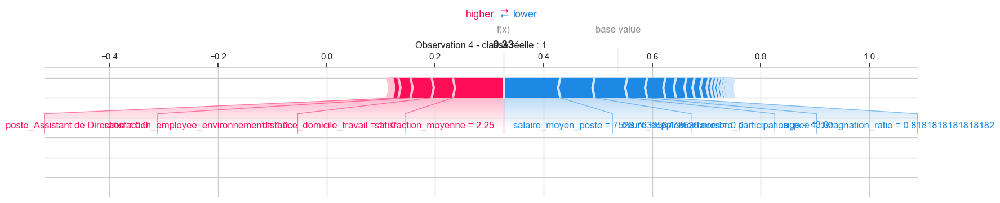

<Figure size 2000x300 with 0 Axes>

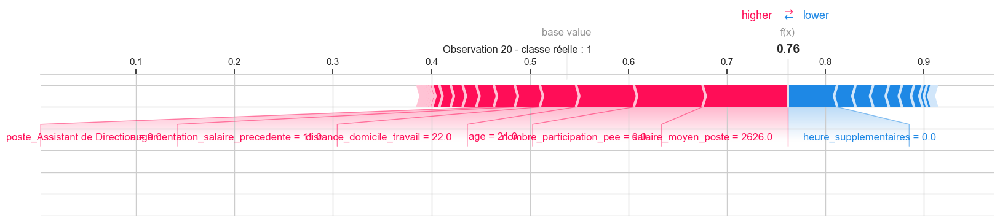

In [123]:
# affichage des importances locales avec shap_force : 2 observations de chaque classe

# nécessaire pour affichage / sauvegarde des force plots
shap.initjs()

# indices des deux classes
idx_0 = np.where(y_test == 0)[0][:2]
idx_1 = np.where(y_test == 1)[0][:2]

indices = list(idx_0) + list(idx_1)

for i in indices:
    
    plt.figure(figsize=(20,3))

    shap.force_plot(
               base_value=shap_values.base_values[i],
               shap_values=shap_values.values[i],
               features=X_shap.iloc[i],
               feature_names=X_shap.columns,
               matplotlib=True,
               show=False,
               contribution_threshold=0.05
               )

    plt.title(f"Observation {i} - classe réelle : {y_test[i]}")
    plt.yticks(rotation=45)
    plt.savefig(
        FIGURES_DIR / f"shap_force_plot_obs_{i}.png",
        dpi=300,
        bbox_inches="tight"
    )
    
    plt.show()
    plt.close()

<Figure size 2000x400 with 0 Axes>

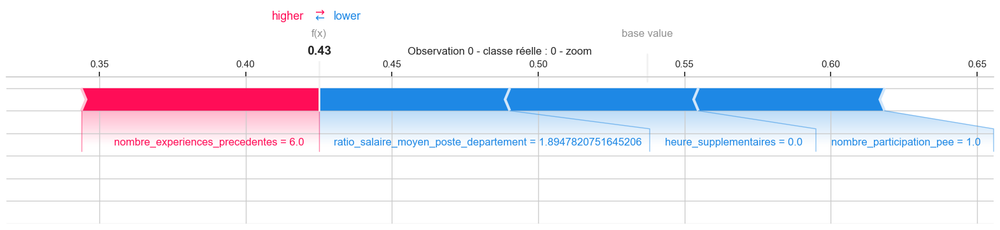

<Figure size 2000x400 with 0 Axes>

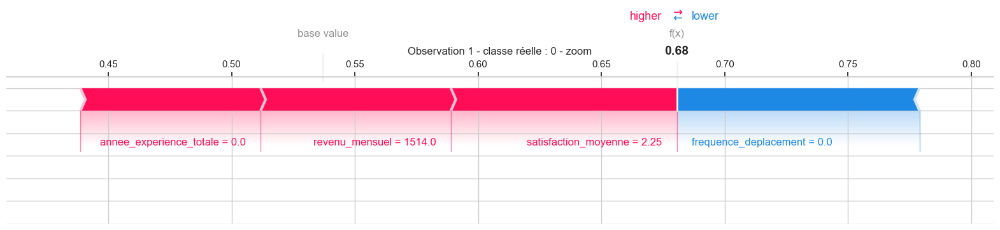

<Figure size 2000x400 with 0 Axes>

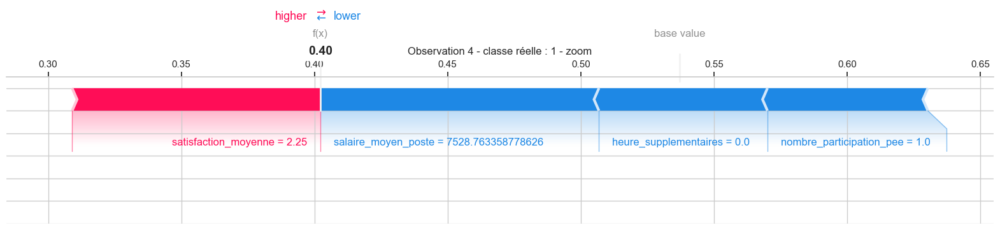

<Figure size 2000x400 with 0 Axes>

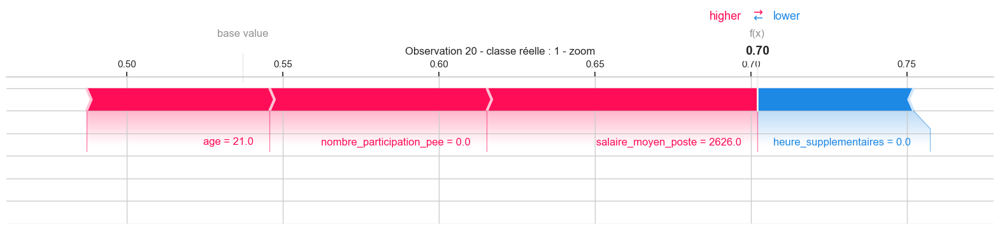

In [124]:
# indices des deux classes
idx_0 = np.where(y_test == 0)[0][:2]
idx_1 = np.where(y_test == 1)[0][:2]

indices = list(idx_0) + list(idx_1)

top_k = 4

for i in indices:

    # récupérer les valeurs shap de l'observation
    shap_vals = shap_values.values[i]

    # indices des 7 variables les plus importantes
    idx_top = np.argsort(np.abs(shap_vals))[::-1][:top_k]

    plt.figure(figsize=(20,4))

    shap.force_plot(
        base_value=shap_values.base_values[i],
        shap_values=shap_vals[idx_top],
        features = X_shap.iloc[i].iloc[idx_top],
        feature_names=X_shap.columns[idx_top],
        matplotlib=True,
        show=False
    )

    plt.title(f"Observation {i} - classe réelle : {y_test[i]} - zoom")
    
    plt.savefig(
        FIGURES_DIR / f"shap_force_plot_zoom_obs_{i}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

## 10. Identification des employés à risque

Classement des employés par probabilité de départ prédite, avec la valeur de leurs 5 variables les plus influentes (SHAP) : une base pour prioriser les actions RH individuelles.

In [135]:
# employés à haut risque de départ
# score d'impact total (importance globale par individu)
shap_risk = pd.DataFrame(shap_values.values, columns=X_shap.columns)

# contribution totale par employé
shap_risk["total_impact"] = shap_risk.sum(axis=1)

# ajouter la probabilité de départ
shap_risk["prob_depart"] = y_proba[:len(shap_risk)]

# top employés à risque
shap_risk.sort_values("prob_depart", ascending=False).head(10)



,age,revenu_mensuel,nombre_experiences_precedentes,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,satisfaction_employee_environnement,note_evaluation_precedente,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,heure_supplementaires,augementation_salaire_precedente,nombre_participation_pee,nb_formations_suivies,distance_domicile_travail,niveau_education,frequence_deplacement,annees_depuis_la_derniere_promotion,note_evaluation_variation,satisfaction_moyenne,evaluation_satisfaction,ratio_satisfaction_anciennete,risque_burnout,salaire_moyen_poste,salaire_moyen_poste_departement,ratio_salaire_moyen_poste_departement,non_satisfait_sous_paye,mobilite_interne,stagnation_ratio,genre_F,genre_M,statut_marital_Célibataire,statut_marital_Divorcé(e),statut_marital_Marié(e),departement_Commercial,departement_Consulting,departement_Ressources Humaines,poste_Assistant de Direction,poste_Cadre Commercial,poste_Consultant,poste_Directeur Technique,poste_Manager,poste_Représentant Commercial,poste_Ressources Humaines,poste_Senior Manager,poste_Tech Lead,domaine_etude_Autre,domaine_etude_Entrepreunariat,domaine_etude_Infra & Cloud,domaine_etude_Marketing,domaine_etude_Ressources Humaines,domaine_etude_Transformation Digitale,total_impact,prob_depart
92,0.044288,-0.010776,0.070534,-0.001147,0.063980,0.002408,-0.007342,-0.004591,-0.006533,-0.000487,-0.001344,0.142125,-0.003928,0.063951,0.002075,-0.017857,0.0,-0.004028,-0.013913,0.004611,-0.001051,0.0,0.000591,-0.000337,-0.072002,-0.003983,-0.006488,0.0,0.0,0.033736,0.0,0.0,0.001885,0.0,0.0,-0.003639,-0.002269,0.0,0.019093,0.0,0.0,0.012079,0.0,0.0,0.0,0.0,-0.011381,0.000546,0.0,0.001780,0.0,0.0,0.0,0.290587,0.981055
135,0.045686,-0.012712,-0.019220,-0.001473,-0.016163,-0.004161,-0.008921,0.107636,0.005832,-0.000556,-0.001479,-0.053243,-0.004474,0.072362,-0.010945,-0.038668,0.0,0.063673,0.041525,0.005066,0.035873,0.0,0.000532,-0.000347,0.048573,0.001767,0.018323,0.0,0.0,-0.019354,0.0,0.0,-0.001206,0.0,0.0,-0.004087,-0.002739,0.0,-0.067264,0.0,0.0,0.012179,0.0,0.0,0.0,0.0,0.002989,0.000658,0.0,-0.002270,0.0,0.0,0.0,0.193391,0.937273
168,-0.036749,-0.014985,0.071091,-0.003416,-0.018980,0.002333,-0.008896,-0.005902,-0.007193,-0.000566,-0.001375,-0.062114,-0.004416,-0.055585,0.002283,-0.021283,0.0,-0.005391,-0.013322,-0.000494,-0.080187,0.0,0.000438,-0.000430,-0.095186,-0.004967,-0.006854,0.0,0.0,0.037048,0.0,0.0,-0.001296,0.0,0.0,-0.004198,-0.002815,0.0,0.021859,0.0,0.0,0.009719,0.0,0.0,0.0,0.0,-0.012923,0.000757,0.0,0.001856,0.0,0.0,0.0,-0.322139,0.935882
199,0.046187,0.088034,-0.018607,0.078216,0.063635,0.002445,-0.008681,-0.004591,0.005562,-0.000525,-0.001441,-0.049329,-0.004324,-0.050449,-0.010667,-0.018608,0.0,-0.004295,-0.013018,-0.000430,-0.000807,0.0,0.000550,-0.000355,0.081795,0.013970,-0.006723,0.0,0.0,0.036972,0.0,0.0,-0.001143,0.0,0.0,-0.003846,-0.002524,0.0,0.020149,0.0,0.0,0.011118,0.0,0.0,0.0,0.0,0.002789,0.000586,0.0,-0.002133,0.0,0.0,0.0,0.249513,0.910380
81,-0.037556,-0.006082,-0.020167,-0.002752,-0.019426,0.002621,-0.009843,-0.028845,0.005931,-0.000631,-0.001590,-0.064505,-0.004857,-0.061482,0.002462,-0.044296,0.0,-0.005719,-0.014841,-0.000548,0.102065,0.0,0.000541,-0.000426,0.045116,0.000937,0.019981,0.0,0.0,-0.021815,0.0,0.0,-0.001375,0.0,0.0,0.012718,0.007936,0.0,0.022860,0.0,0.0,0.011472,0.0,0.0,0.0,0.0,0.003196,0.000747,0.0,0.002064,0.0,0.0,0.0,-0.106105,0.896460
67,0.029542,0.050277,-0.010290,0.043874,0.037210,0.001560,-0.004648,0.058501,-0.003874,-0.000275,-0.000846,0.087997,-0.002369,0.041018,0.001319,0.020633,0.0,0.034535,-0.009205,0.002795,-0.042492,0.0,0.000367,-0.000171,0.051078,0.008513,-0.004233,0.0,0.0,0.020963,0.0,0.0,0.001207,0.0,0.0,0.006864,0.004091,0.0,0.010671,0.0,0.0,0.008388,0.0,0.0,0.0,0.0,0.001778,0.000311,0.0,-0.001194,0.0,0.0,0.0,0.443896,0.894709
35,0.043569,-0.011009,-0.016839,0.070953,0.025592,0.002283,-0.008183,-0.004572,-0.006107,-0.000480,-0.001385,0.149305,-0.00416

In [139]:
# employés à haut risque de départ
# top 10 des positions les plus à risque
top_pos = shap_risk.sort_values("prob_depart", ascending=False).head(10).index

# vraies valeurs des variables
top_employees = X_shap.iloc[top_pos].copy()

# importance globale des features
shap_importance = np.abs(shap_values.values).mean(axis=0)
    
# top 5 features
top_features = X_shap.columns[np.argsort(shap_importance)[-5:]]

# garder uniquement les 5 features + probabilité
top_employees = X_shap.iloc[top_pos][top_features].copy()

# ajouter probabilité de départ
top_employees["prob_depart"] = y_proba[top_pos]

top_employees

,nombre_experiences_precedentes,satisfaction_moyenne,nombre_participation_pee,salaire_moyen_poste,heure_supplementaires,prob_depart
602,5,2.75,0,7295.137931,1,0.981055
1389,1,2.50,0,3239.972603,0,0.937273
340,7,3.25,2,7295.137931,0,0.935882
41,1,3.00,1,3237.169884,0,0.910380
403,1,2.25,1,6924.279141,0,0.896460
911,1,3.50,0,2626.000000,1,0.894709
929,1,3.25,1,3237.169884,1,0.886993
700,4,2.75,0,3239.972603,0,0.874963
522,3,3.00,0,3239.972603,0,0.873473
846,2,2.75,1,7295.137931,0,0.868159


## 11. Conclusion

**Modèle.** Un XGBoost entraîné sur un split stratifié, avec pondération des classes et seuil optimisé pour le F2, détecte **environ 70 % des démissionnaires** (précision 0,41). C'est près de 2 fois le rappel de la régression logistique. Adapté à un usage préventif : une fausse alerte coûte un entretien RH, un départ manqué coûte un recrutement.

**Principales causes d'attrition identifiées**
1. **Charge de travail** : heures supplémentaires, surtout combinées à une faible satisfaction (risque de burnout).
2. **Rémunération** : salaire faible ou inférieur à celui des pairs du même poste.
3. **Engagement** : faible satisfaction et faible participation au PEE.
4. **Profil et carrière** : collaborateurs jeunes, peu d'ancienneté, parcours multi-employeurs, stagnation dans le poste.
5. **Contraintes personnelles** : distance domicile-travail et déplacements fréquents.

**Leviers RH** : encadrer les heures supplémentaires, revoir les écarts salariaux à poste égal, renforcer la mobilité interne et les perspectives d'évolution, suivre la satisfaction des nouveaux arrivants.

**Limites et pistes d'amélioration**
- Jeu de données de petite taille (1 470 employés, ~240 départs) : résultats sensibles au découpage.
- Le seuil de décision est optimisé sur le jeu de test : la performance annoncée est donc légèrement optimiste. Un seuil choisi par validation croisée serait plus rigoureux.
- Pistes : encapsuler le prétraitement dans un `Pipeline` scikit-learn, calibrer les probabilités, tester d'autres modèles (LightGBM, CatBoost).